# Лабораторная работа 2. Классификация и нейронная сеть

**Датасет:** [Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro, Cortez, Rita, 2014)
**Файл:** `data/bank-additional.csv` — официальная случайная подвыборка 10% (4119 клиентов). В описании UCI она как раз рекомендована для тяжёлых методов вроде SVM.
**Целевая переменная:** `y` — согласился ли клиент открыть срочный депозит после телефонного разговора (`yes` / `no`).

Инструменты: pandas, NumPy, scikit-learn, matplotlib, seaborn, TensorFlow/Keras, TensorBoard.
Генератор случайных чисел зафиксирован: `RANDOM_STATE = 42`.

## 1. Введение

**Цель работы** — научиться решать задачу классификации средствами scikit-learn, сравнить методы по нескольким метрикам и посмотреть, как устроена полносвязная нейронная сеть в TensorFlow, включая контроль обучения в TensorBoard.

**Задачи:**

1. Выбрать датасет, описать признаки и подготовить их.
2. Разделить данные на обучение и тест.
3. Построить пять семейств классификаторов: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод k ближайших соседей.
4. Для каждого семейства посмотреть, как гиперпараметры меняют качество, и выбрать настройку кросс-валидацией на обучении.
5. Сравнить модели по Accuracy, Precision, Recall, F1-Score и AUC-ROC, построить ROC-кривые и столбчатые диаграммы.
6. Обучить нейронную сеть, перебрать архитектуру и режим обучения, записать ход обучения в TensorBoard и сравнить сеть с лучшим классическим методом.

Положительный класс — клиент **оформил депозит** (`yes` = 1). Таких клиентов около 11%, поэтому ответ «всегда отказ» уже даёт высокую долю верных ответов и нулевую чувствительность. Accuracy здесь легко принять за качество, хотя модель не находит ни одного нужного клиента.

| Метрика | Смысл на этих данных |
|---|---|
| Accuracy | доля верных ответов среди всех клиентов |
| Precision | среди тех, кому модель предсказала согласие, какая доля согласилась на самом деле |
| Recall | какую долю реально согласившихся модель сумела найти |
| F1-Score | среднее гармоническое precision и recall по классу «да» |
| AUC-ROC | насколько уверенно модель ставит согласившихся выше отказников; от порога 0,5 не зависит |

Гиперпараметры выбираются по AUC-ROC на 5-блочной стратифицированной кросс-валидации. Тестовая выборка в этом выборе не участвует. Если несколько настроек отличаются от лучшей не больше чем на 0,005 AUC, берётся та, у которой обучающий AUC меньше всего обгоняет проверочный: так отсекается переобучение.

## 2. Выбор и подготовка датасета

Каждая строка — один клиент португальского банка и последняя попытка предложить ему срочный депозит в кампании 2008–2010 годов. Набор взят не из списка типовых вариантов (ирисы, вино, Титаник, диабет, рак молочной железы): там классы либо игрушечные, либо уже много раз разобраны. Здесь классы несбалансированы, признаки разнотипные, а один столбец — длительность звонка — нельзя честно подавать в модель. Это как раз то, на чём видно различие метрик.

Признаки клиента: возраст (`age`), работа (`job`), семейное положение (`marital`), образование (`education`), был ли дефолт (`default`), ипотека (`housing`), потребительский кредит (`loan`).

Признаки текущего контакта: канал (`contact` — мобильный или стационарный), месяц (`month`), день недели (`day_of_week`), число попыток в этой кампании (`campaign`) и длительность разговора (`duration`, секунды).

История прошлых кампаний: сколько дней назад звонили (`pdays`, значение 999 означает «не звонили»), сколько было прошлых контактов (`previous`), чем прошлая кампания закончилась (`poutcome`).

Макроэкономика на дату звонка: изменение занятости (`emp.var.rate`), индекс цен (`cons.price.idx`), индекс доверия (`cons.conf.idx`), ставка Euribor (`euribor3m`), число занятых (`nr.employed`).

Пропуски в категориях записаны словом `unknown`, а не пустой ячейкой. Это отдельное состояние («банк не знает»), его нельзя молча заменять модой.

### 2.1. Загрузка

In [1]:
import os
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("data/bank-additional.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("Lab2_Classification") / "data" / "bank-additional.csv"

df_raw = pd.read_csv(DATA_PATH, sep=";")
print(f"Размерность: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов")
print(f"Файл: {DATA_PATH.resolve()}")
display(df_raw.head())

Размерность: 4119 строк, 21 столбцов
Файл: D:\sharaga\AIslop\Lab2_Classification\data\bank-additional.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,487,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,346,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,227,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,17,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,58,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


Загружены 4119 клиентов и 21 столбец, последний из них — ответ `y`. Это не вся база банка (в полном файле 41 188 строк), а фиксированная десятая часть, которую авторы выложили отдельно. Для сеток SVM и для нейронной сети такого объёма достаточно, и один и тот же файл можно прогнать за разумное время.

Категории пришли текстом, числа — числами. Пустых ячеек `NaN` в файле нет: неизвестные значения уже подписаны как `unknown`.

### 2.2. Очистка, утечка длительности и кодирование

In [2]:
print("Пустые ячейки:", int(df_raw.isna().sum().sum()))
print("Полных дубликатов:", int(df_raw.duplicated().sum()))
print(df_raw["y"].value_counts().rename("клиентов").to_frame())

eda = df_raw.copy()
eda["subscribed"] = (eda["y"] == "yes").astype(int)
print(f"Доля согласий: {eda['subscribed'].mean():.1%}")
print("Длительность 0 секунд и ответ:", eda.loc[eda["duration"] == 0, "y"].value_counts().to_dict())
print(f"Клиентов с pdays = 999 (раньше не звонили): {(eda['pdays'] == 999).sum()} из {len(eda)}")


def design_matrix(frame, drop_duration):
    data = frame.copy()
    data["never_contacted"] = (data["pdays"] == 999).astype(int)
    data["pdays"] = data["pdays"].replace(999, 0)
    if drop_duration:
        data = data.drop(columns=["duration"])
    target = (data.pop("y") == "yes").astype(int)
    data.columns = [column.replace(".", "_") for column in data.columns]
    categorical = [column for column in data.columns if not pd.api.types.is_numeric_dtype(data[column])]
    matrix = pd.get_dummies(data, columns=categorical, drop_first=True, dtype=float)
    return matrix.astype(float), target


y_all = (df_raw["y"] == "yes").astype(int)
idx_train, idx_test = train_test_split(
    np.arange(len(df_raw)), test_size=0.20, random_state=RANDOM_STATE, stratify=y_all
)

X_with, y_with = design_matrix(df_raw, drop_duration=False)
X, y = design_matrix(df_raw, drop_duration=True)
assert list(y) == list(y_with)

duration_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LinearDiscriminantAnalysis()),
])
cv_probe = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
auc_with_duration = cross_validate(
    duration_pipe, X_with.iloc[idx_train], y_with.iloc[idx_train],
    cv=cv_probe, scoring="roc_auc", n_jobs=1,
)["test_score"].mean()
auc_without_duration = cross_validate(
    clone(duration_pipe), X.iloc[idx_train], y.iloc[idx_train],
    cv=cv_probe, scoring="roc_auc", n_jobs=1,
)["test_score"].mean()
print(f"LDA, CV AUC со столбцом duration:    {auc_with_duration:.4f}")
print(f"LDA, CV AUC без столбца duration:    {auc_without_duration:.4f}")
print(f"Прирост от утечки:                   {auc_with_duration - auc_without_duration:+.4f}")

X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train].copy(), y.iloc[idx_test].copy()
print(f"Признаков после кодирования, без duration: {X_train.shape[1]}")
print(f"Обучение: {len(y_train)} | тест: {len(y_test)}")
print(f"Доля «да» в обучении / тесте: {y_train.mean():.1%} / {y_test.mean():.1%}")
print("Пропусков в матрице признаков:", int(X.isna().sum().sum()))

Пустые ячейки: 0
Полных дубликатов: 0
     клиентов
y            
no       3668
yes       451
Доля согласий: 10.9%
Длительность 0 секунд и ответ: {'no': 1}
Клиентов с pdays = 999 (раньше не звонили): 3959 из 4119


LDA, CV AUC со столбцом duration:    0.9267
LDA, CV AUC без столбца duration:    0.7642
Прирост от утечки:                   +0.1625
Признаков после кодирования, без duration: 53
Обучение: 3295 | тест: 824
Доля «да» в обучении / тесте: 11.0% / 10.9%
Пропусков в матрице признаков: 0


Дубликатов нет, пустых ячеек нет. Согласий 451 из 4119, это 10,9%. Константа «клиент отказался» на всей таблице даёт accuracy 89,1% и recall 0. Любая модель, которая не обгоняет эту планку по поиску согласий, для банка бесполезна, даже если accuracy выглядит прилично.

`pdays = 999` стоит у 3959 клиентов. Это не «звонили тысячу дней назад», а код «в прошлых кампаниях не участвовал». Код заменён признаком `never_contacted` и нулём в `pdays`, иначе регрессионная шкала и дискриминантный анализ приняли бы отсутствие истории за очень большое число.

Категории, включая `unknown`, развернуты в дамми с `drop_first=True`, чтобы не получить линейно зависимые столбцы в LDA и SVM. Редкие уровни при этом сохраняются: дефолт `yes` и образование `illiterate` встречаются по одному разу, на метрики они почти не влияют, а уровень `unknown` у дефолта встречается сотни раз и является нормальным состоянием признака.

Столбец `duration` из моделей убран. Авторы датасета отдельно предупреждают: длительность неизвестна до звонка, а нулевая длительность означает отказ (в этой подвыборке единственный разговор на 0 секунд — это отказ). Один и тот же LDA на одних и тех же обучающих клиентах даёт CV AUC 0,927, если длительность оставить, и 0,764, если её убрать. Прирост 0,16 — это подглядывание в уже состоявшийся разговор, а не честный прогноз. Дальше везде используется матрица без длительности: 53 признака после кодирования.

### 2.3. Как признаки связаны с согласием

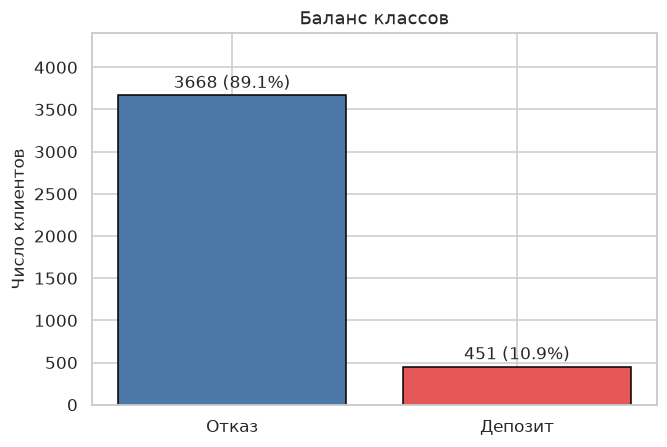

,уровень,доля,клиентов,признак
0,student,0.232,82,Работа
1,retired,0.229,166,Работа
2,unemployed,0.171,111,Работа
3,admin.,0.131,1012,Работа
4,technician,0.116,691,Работа
5,unknown,0.103,39,Работа
6,housemaid,0.100,110,Работа
7,management,0.093,324,Работа
8,services,0.089,393,Работа
9,self-employed,0.082,159,Работа


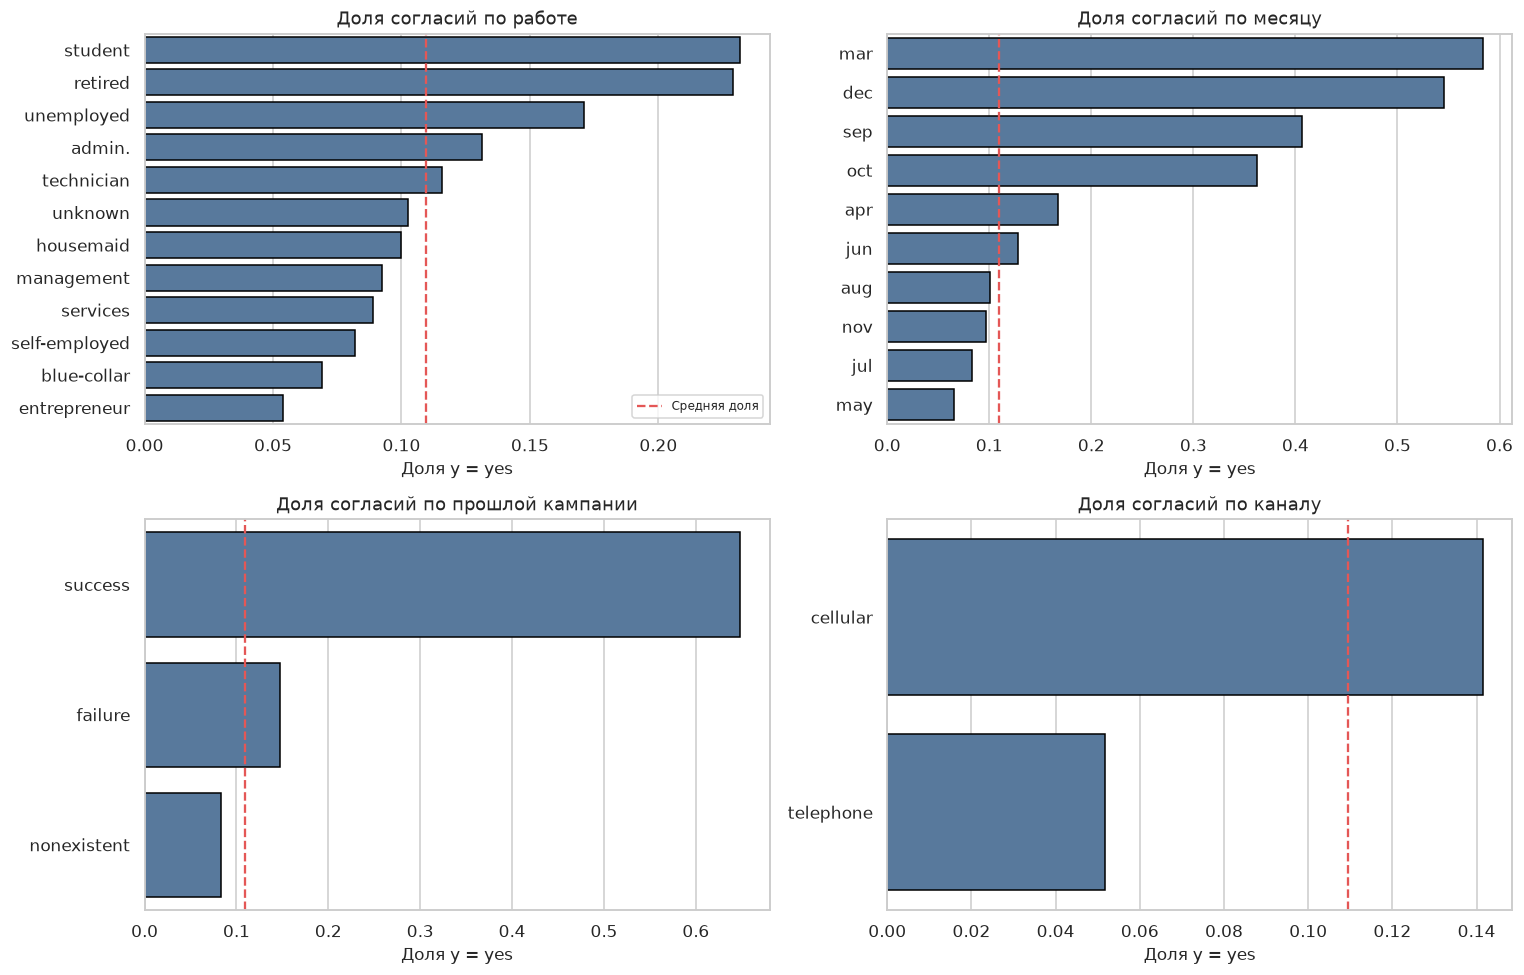

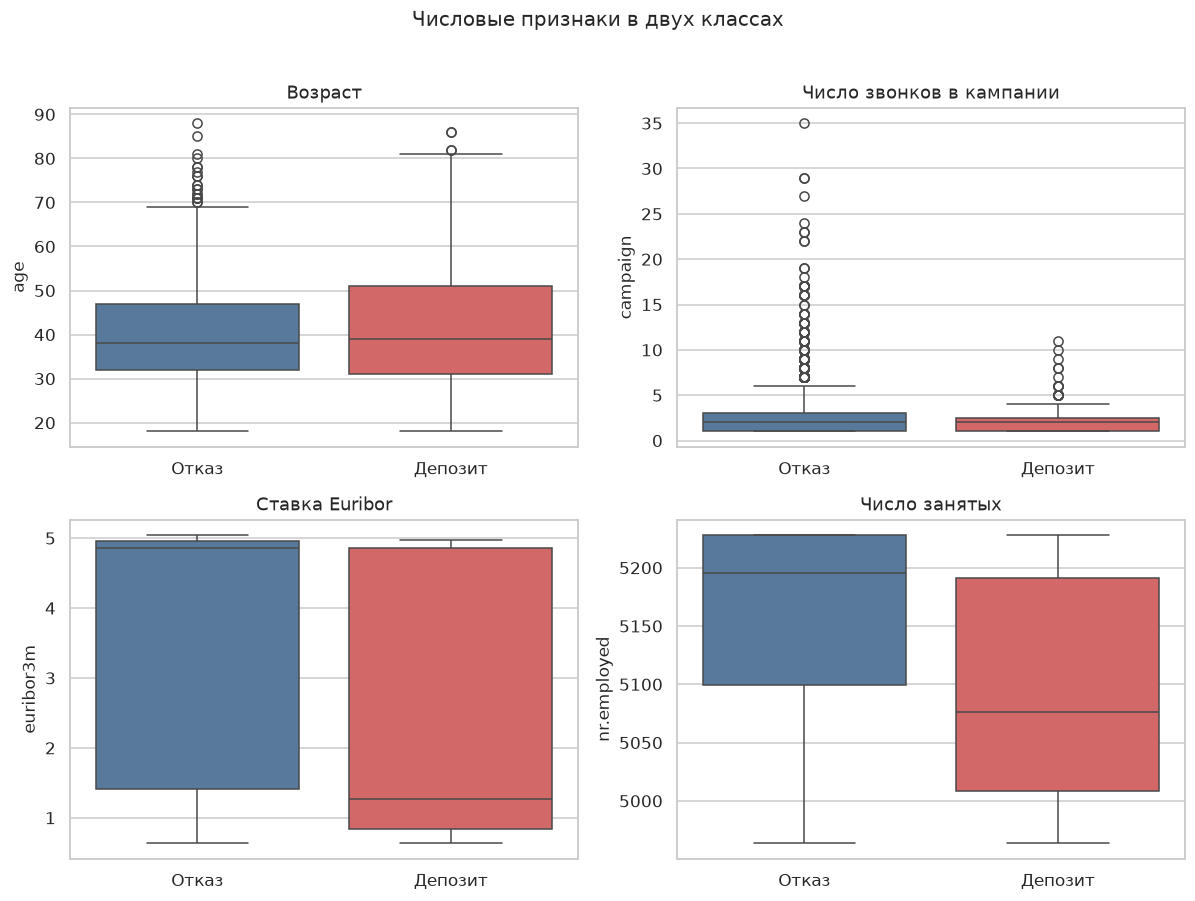

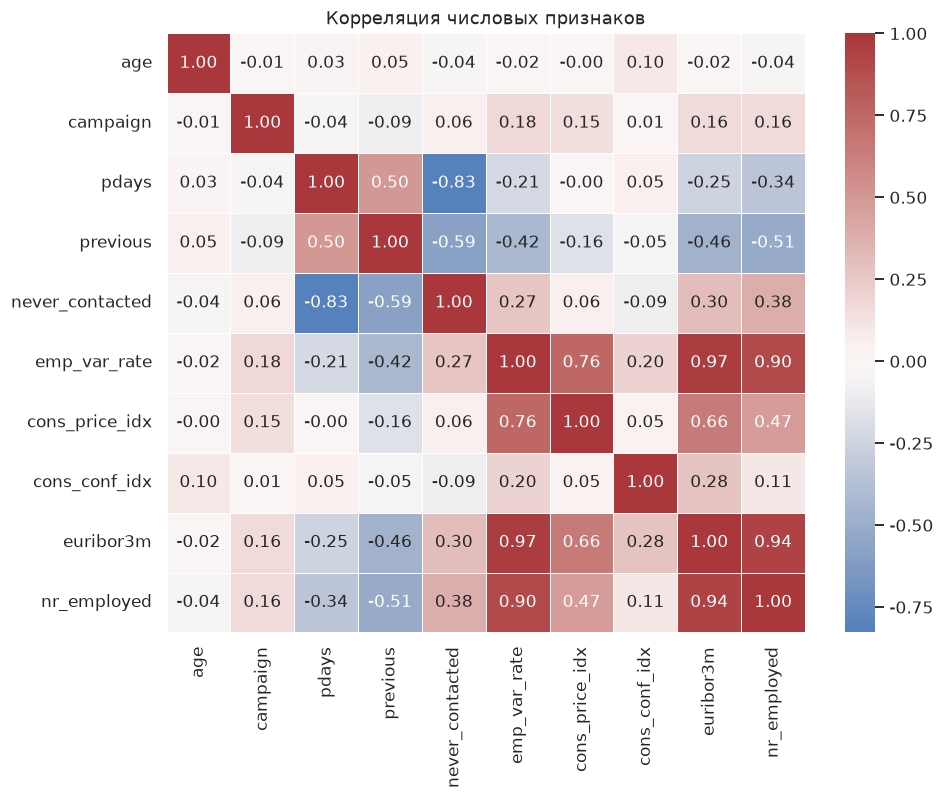

Среднее campaign, отказ / депозит: 2.61 / 1.98
Средний euribor3m, отказ / депозит: 3.80 / 2.15


In [3]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
balance = pd.Series({"Отказ": int((y == 0).sum()), "Депозит": int((y == 1).sum())})
bars = ax.bar(balance.index, balance.values, color=["#4C78A8", "#E45756"], edgecolor="black")
for bar, value in zip(bars, balance.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 40, f"{int(value)} ({value / len(y):.1%})",
            ha="center", va="bottom")
ax.set_ylim(0, balance.max() * 1.2)
ax.set_ylabel("Число клиентов")
ax.set_title("Баланс классов")
plt.tight_layout()
plt.show()

rate_frames = []
for column, title in [
    ("job", "Работа"),
    ("month", "Месяц контакта"),
    ("poutcome", "Итог прошлой кампании"),
    ("contact", "Канал связи"),
]:
    stat = (eda.groupby(column)["subscribed"]
            .agg(доля="mean", клиентов="size")
            .sort_values("доля", ascending=False))
    stat["признак"] = title
    rate_frames.append(stat.reset_index().rename(columns={column: "уровень"}))
rates = pd.concat(rate_frames, ignore_index=True)
display(rates.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
pieces = [
    (axes[0, 0], "job", "Доля согласий по работе"),
    (axes[0, 1], "month", "Доля согласий по месяцу"),
    (axes[1, 0], "poutcome", "Доля согласий по прошлой кампании"),
    (axes[1, 1], "contact", "Доля согласий по каналу"),
]
for ax, column, title in pieces:
    stat = (eda.groupby(column)["subscribed"].mean().sort_values(ascending=False))
    sns.barplot(x=stat.values, y=stat.index, ax=ax, color="#4C78A8", edgecolor="black")
    ax.axvline(eda["subscribed"].mean(), color="#E45756", ls="--", lw=1.5, label="Средняя доля")
    ax.set_title(title)
    ax.set_xlabel("Доля y = yes")
    ax.set_ylabel("")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

plot_df = eda.copy()
plot_df["Класс"] = plot_df["subscribed"].map({0: "Отказ", 1: "Депозит"})
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, column, title in zip(
    axes.ravel(),
    ["age", "campaign", "euribor3m", "nr.employed"],
    ["Возраст", "Число звонков в кампании", "Ставка Euribor", "Число занятых"],
):
    sns.boxplot(
        data=plot_df, x="Класс", y=column, hue="Класс",
        order=["Отказ", "Депозит"], hue_order=["Отказ", "Депозит"],
        palette={"Отказ": "#4C78A8", "Депозит": "#E45756"}, legend=False, ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
fig.suptitle("Числовые признаки в двух классах", y=1.02)
plt.tight_layout()
plt.show()

numeric_cols = [
    "age", "campaign", "pdays", "previous", "never_contacted",
    "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed",
]
corr = X[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, linewidths=0.4)
ax.set_title("Корреляция числовых признаков")
plt.tight_layout()
plt.show()
print("Среднее campaign, отказ / депозит:",
      f"{eda.loc[eda['subscribed']==0, 'campaign'].mean():.2f} / {eda.loc[eda['subscribed']==1, 'campaign'].mean():.2f}")
print("Средний euribor3m, отказ / депозит:",
      f"{eda.loc[eda['subscribed']==0, 'euribor3m'].mean():.2f} / {eda.loc[eda['subscribed']==1, 'euribor3m'].mean():.2f}")

Согласие редко и распределено неравномерно по группам.

Студенты и пенсионеры соглашаются чаще (около 23%), рабочие специальности — реже (около 7%). По каналу связи разрыв тоже ясный: мобильный телефон 14,1%, стационарный 5,2%. Ипотека и личный кредит долю почти не меняют, их вклад в модель будет слабым.

Прошлая кампания — самый резкий одиночный признак. Если раньше клиент уже согласился, доля повторного согласия 64,8% (142 человека). Если истории нет, доля падает до 8,3%. Месяцы марта, сентября, октября и декабря дают высокую долю, но клиентов там мало; май — самый массовый месяц и одна из самых низких долей (6,5%). Месяц поэтому полезен, но редкие месяцы неустойчивы.

Согласившиеся в среднем чуть старше, им сделали меньше повторных звонков в текущей кампании (1,98 против 2,61) и звонили на фоне более низкой ставки Euribor (2,14 против 3,80). Большое число попыток — скорее признак того, что человек сразу не согласился, а не доказательство настойчивости банка.

На тепловой карте `euribor3m`, `nr_employed` и `emp_var_rate` идут вместе: это три описания одной и той же экономической обстановки 2008–2010 годов. Для дерева такая группа не мешает, для LDA и линейного SVM она означает, что веса этих трёх столбцов по отдельности читать не стоит. `never_contacted` почти повторяет `previous`: оба говорят, была ли прошлая кампания.

## 3. Разбиение выборки

Деление стратифицированное, 80/20, `random_state = 42`. Стратификация нужна, чтобы в тесте осталась та же доля согласий, что и в обучении. Иначе при 11% положительного класса тест мог бы случайно получить слишком мало согласий, и recall стал бы шумным.

Масштабирование в это деление не входит. `StandardScaler` и `MinMaxScaler` стоят внутри pipeline и на кросс-валидации обучаются только на текущем тренировочном блоке. Иначе статистика теста и соседних блоков попала бы в шкалу признаков.

In [4]:
def split_row(name, target):
    return {
        "Выборка": name,
        "Клиентов": int(len(target)),
        "Депозит": int(target.sum()),
        "Отказ": int((target == 0).sum()),
        "Доля депозита": float(target.mean()),
    }


split_table = pd.DataFrame([
    split_row("Все данные", y),
    split_row("Обучение", y_train),
    split_row("Тест", y_test),
])
display(split_table.round(4))
majority_accuracy = float((y_test == 0).mean())
print(f"Константа «всегда отказ» на тесте: accuracy {majority_accuracy:.4f}, precision 0, recall 0, F1 0, AUC 0.5")

,Выборка,Клиентов,Депозит,Отказ,Доля депозита
0,Все данные,4119,451,3668,0.1095
1,Обучение,3295,361,2934,0.1096
2,Тест,824,90,734,0.1092


Константа «всегда отказ» на тесте: accuracy 0.8908, precision 0, recall 0, F1 0, AUC 0.5


В обучении 3295 клиентов, в тесте 824. Согласий в тесте 90, доля 10,9% и там и там: стратификация сработала. Константа «всегда отказ» на тесте получает accuracy 0,891, precision 0, recall 0 и F1 0. Это нижняя планка для accuracy. По поиску согласий планка нулевая.

## 4. Методы классификации

Все пять семейств ниже решают одну задачу и получают одну и ту же матрицу признаков без `duration`. Отличаются допущения.

**Наивный Байес** считает признаки независимыми при известном классе и перемножает их вклады. Четыре реализации рассчитаны на разные типы данных.

- `GaussianNB` считает, что каждый признак внутри класса нормальный. Ему подходят возраст, ставка, число звонков. Дамми-столбцы нормальными не являются, это компромисс.
- `MultinomialNB` рассчитан на счётчики (сколько раз встретилось слово). Отрицательные значения он не принимает, а индекс доверия и изменение занятости здесь отрицательны, поэтому признаки сначала переводятся в отрезок от 0 до 1.
- `ComplementNB` оценивает не сам класс, а его дополнение. Его как раз делали для редкого положительного класса.
- `BernoulliNB` видит только нули и единицы. После MinMax каждый признак сравнивается с порогом: выше порога — 1, иначе 0.

**Дерево решений** режет пространство порогами вида «euribor меньше числа». Масштаб признаков ему не важен. Глубокое дерево запоминает обучение, поэтому глубина и минимальное число объектов в листе — главные ограничения.

**LDA** проводит одну линейную границу. Классы предполагаются нормальными с общей ковариацией. `shrinkage` поджимает эту ковариацию к диагонали, когда столбцы коррелируют, как три макроэкономических показателя.

**SVM** ищет границу с наибольшим зазором. Линейное ядро — одна гиперплоскость. Ядро RBF собирает более гибкую границу; параметр `C` решает, насколько дорого ошибаться на обучении. Признаки перед SVM стандартизируются, иначе `nr_employed` (тысячи) задавит число звонков (единицы).

**k ближайших соседей** относит клиента к классу большинства среди k самых похожих. При k = 1 модель запоминает выборку. Признаки тоже стандартизируются, иначе «близость» определяется только столбцами с большим размахом.

`class_weight="balanced"` у дерева и SVM повышает цену ошибки на редком классе «да». Порог предсказания при этом остаётся стандартным: для вероятностных моделей это 0,5, для SVM — знак отступа. AUC от этого порога не зависит, precision и recall зависят.

## 5. Настройка гиперпараметров

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
}
CHOSEN = {}
TUNING_ROWS = []


def evaluate_cv(estimator):
    result = cross_validate(
        estimator, X_train, y_train, cv=CV, scoring=SCORING,
        n_jobs=1, return_train_score=True, error_score="raise",
    )
    metrics = {}
    for key in SCORING:
        metrics[key] = float(result[f"test_{key}"].mean())
        metrics[f"{key}_std"] = float(result[f"test_{key}"].std())
        metrics[f"{key}_train"] = float(result[f"train_{key}"].mean())
    return metrics


def select_best(frame):
    pool = frame[frame["roc_auc"] >= frame["roc_auc"].max() - 0.005].copy()
    pool["gap"] = pool["roc_auc_train"] - pool["roc_auc"]
    return pool.sort_values(["gap", "roc_auc", "f1"], ascending=[True, False, False]).iloc[0]


def sweep(combos, factory):
    measured = []
    params = []
    for kw in combos:
        measured.append({**kw, **evaluate_cv(factory(**kw))})
        params.append(dict(kw))
    frame = pd.DataFrame(measured)
    frame["_i"] = np.arange(len(params))
    return frame, params


def remember(name, factory, combos, default_kw, param_note):
    frame, params = sweep(combos, factory)
    best = select_best(frame)
    best_kw = params[int(best["_i"])]
    default_metrics = evaluate_cv(factory(**default_kw))
    model = factory(**best_kw)
    model.fit(X_train, y_train)
    CHOSEN[name] = {"model": model, "params": best_kw, "cv_auc": float(best["roc_auc"])}
    TUNING_ROWS.append({
        "Метод": name,
        "По умолчанию": param_note(default_kw),
        "AUC по умолчанию": default_metrics["roc_auc"],
        "Выбрано": param_note(best_kw),
        "AUC после выбора": float(best["roc_auc"]),
        "Прирост AUC": float(best["roc_auc"] - default_metrics["roc_auc"]),
        "F1 CV": float(best["f1"]),
        "Recall CV": float(best["recall"]),
        "Разрыв train-val": float(best["roc_auc_train"] - best["roc_auc"]),
    })
    print(
        f"ВЫБОР {name}: {param_note(best_kw)} | "
        f"CV AUC {best['roc_auc']:.4f}±{best['roc_auc_std']:.4f} | "
        f"F1 {best['f1']:.4f} | P {best['precision']:.4f} | R {best['recall']:.4f} | "
        f"Acc {best['accuracy']:.4f} | разрыв {best['roc_auc_train'] - best['roc_auc']:.4f} | "
        f"база {default_metrics['roc_auc']:.4f} | прирост {best['roc_auc'] - default_metrics['roc_auc']:+.4f}"
    )
    return frame


def show_metrics(frame, columns):
    view = frame[columns + ["roc_auc", "roc_auc_std", "f1", "precision", "recall", "accuracy", "roc_auc_train"]].copy()
    display(view.sort_values("roc_auc", ascending=False).round(4).reset_index(drop=True))

Дальше каждая сетка считается только на обучении. В выводе ячейки строка `ВЫБОР` — это настройка, которая прошла правило из введения: высокий проверочный AUC и небольшой отрыв обучения от проверки. Столбец `roc_auc_train` в таблице нужен именно для этого отрыва. Тест по-прежнему не открывается.

### 5.1. GaussianNB

ВЫБОР GaussianNB: var_smoothing=1e-03, scale=False | CV AUC 0.7633±0.0417 | F1 0.4449 | P 0.4611 | R 0.4350 | Acc 0.8816 | разрыв 0.0004 | база 0.7502 | прирост +0.0131


,var_smoothing,scale,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,0.000,False,0.7681,0.0392,0.4291,0.4042,0.4655,0.8659,0.7751
1,0.001,False,0.7633,0.0417,0.4449,0.4611,0.4350,0.8816,0.7637
2,0.000,False,0.7526,0.0270,0.4141,0.3902,0.4488,0.8622,0.7732
3,0.100,True,0.7524,0.0275,0.4073,0.3749,0.4543,0.8564,0.7732
4,0.000,False,0.7517,0.0271,0.3925,0.3246,0.5237,0.8228,0.7721
5,0.001,True,0.7511,0.0273,0.3854,0.2942,0.5846,0.7918,0.7715
6,0.000,False,0.7509,0.0274,0.3481,0.2523,0.6345,0.7080,0.7714
7,0.000,True,0.7508,0.0274,0.3255,0.2208,0.7065,0.6419,0.7710
8,0.000,True,0.7507,0.0273,0.2669,0.1646,0.8200,0.4592,0.7705
9,0.000,True,0.7502,0.0276,0.2441,0.1450,0.9002,0.3341,0.7699


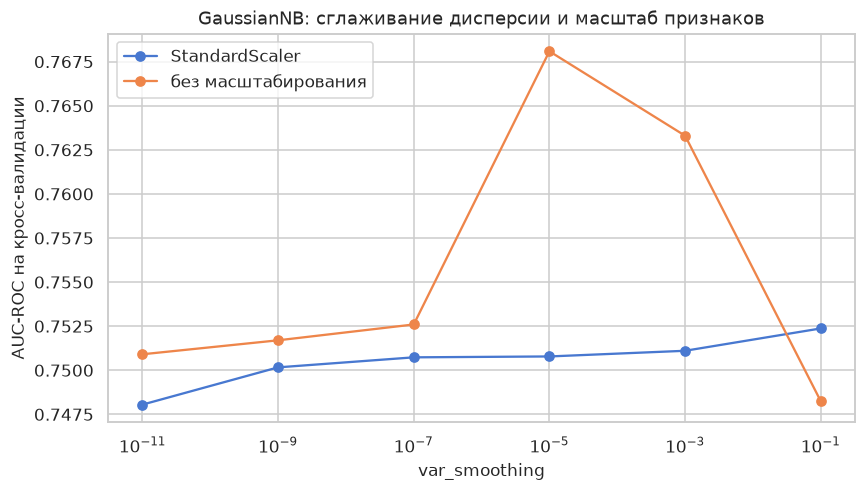

In [6]:
def make_gaussian(var_smoothing=1e-9, scale=True):
    clf = GaussianNB(var_smoothing=float(var_smoothing))
    if scale:
        return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return clf


gaussian_grid = [
    {"var_smoothing": float(v), "scale": scale}
    for scale in (False, True)
    for v in np.logspace(-11, -1, 6)
]
gaussian_df = remember(
    "GaussianNB", make_gaussian, gaussian_grid,
    {"var_smoothing": 1e-9, "scale": True},
    lambda kw: f"var_smoothing={kw['var_smoothing']:.0e}, scale={kw['scale']}",
)
show_metrics(gaussian_df, ["var_smoothing", "scale"])

fig, ax = plt.subplots(figsize=(8, 4.6))
for scale, label in [(True, "StandardScaler"), (False, "без масштабирования")]:
    sub = gaussian_df[gaussian_df["scale"] == scale].sort_values("var_smoothing")
    ax.plot(sub["var_smoothing"], sub["roc_auc"], marker="o", label=label)
ax.set_xscale("log")
ax.set_xlabel("var_smoothing")
ax.set_ylabel("AUC-ROC на кросс-валидации")
ax.set_title("GaussianNB: сглаживание дисперсии и масштаб признаков")
ax.legend()
plt.tight_layout()
plt.show()

`var_smoothing` добавляет долю максимальной дисперсии к дисперсии каждого признака. Без этой добавки признак, который внутри класса почти не меняется, получает огромный вес: маленькая дисперсия стоит в знаменателе нормальной плотности. Слишком большое сглаживание, наоборот, стирает различия классов.

Отдельная кривая без стандартизации нужна потому, что наивный Байес оценивает дисперсию в исходных единицах. Число занятых измеряется тысячами, число звонков — единицами. На этой сетке стандартизация AUC почти не поднимает, зато сильно растит recall и роняет precision: модель слишком часто говорит «да».

Выбрано сглаживание `var_smoothing = 10⁻³` без стандартизации. CV AUC 0,763, разрыв обучения и проверки около нуля. Заводская настройка (сглаживание `10⁻⁹` и StandardScaler) давала 0,750. Прирост небольшой, 0,013, и он как раз убирает крайность, когда модель относит к депозиту почти всех.

### 5.2. MultinomialNB

ВЫБОР MultinomialNB: alpha=5 | CV AUC 0.7557±0.0286 | F1 0.4015 | P 0.5170 | R 0.3326 | Acc 0.8929 | разрыв 0.0109 | база 0.7589 | прирост -0.0032


,alpha,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,1.00,0.7589,0.0292,0.3912,0.4957,0.3270,0.8898,0.7720
1,0.10,0.7581,0.0300,0.3912,0.4948,0.3270,0.8898,0.7734
2,0.01,0.7563,0.0314,0.3912,0.4948,0.3270,0.8898,0.7738
3,5.00,0.7557,0.0286,0.4015,0.5170,0.3326,0.8929,0.7667
4,10.00,0.7522,0.0289,0.3926,0.5173,0.3216,0.8929,0.7617


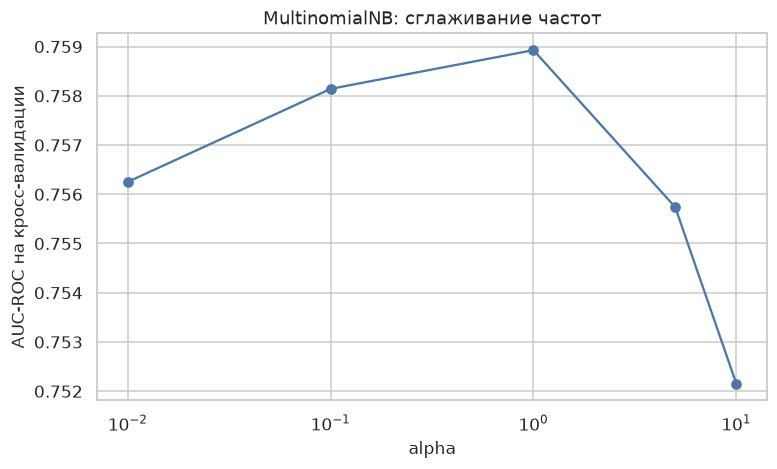

In [7]:
def make_multinomial(alpha=1.0):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("clf", MultinomialNB(alpha=float(alpha))),
    ])


multi_grid = [{"alpha": float(a)} for a in (0.01, 0.1, 1.0, 5.0, 10.0)]
multi_df = remember(
    "MultinomialNB", make_multinomial, multi_grid,
    {"alpha": 1.0},
    lambda kw: f"alpha={kw['alpha']:g}",
)
show_metrics(multi_df, ["alpha"])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
sub = multi_df.sort_values("alpha")
ax.plot(sub["alpha"], sub["roc_auc"], marker="o", color="#4C78A8")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("AUC-ROC на кросс-валидации")
ax.set_title("MultinomialNB: сглаживание частот")
plt.tight_layout()
plt.show()

Мультиномиальный Байес предполагает неотрицательные счётчики. Индекс потребительского доверия здесь около −40, изменение занятости бывает отрицательным, поэтому без сжатия в отрезок [0, 1] метод просто не запускается. MinMax делает запуск возможным, но не превращает ставку Euribor в частоту слова. Это проверка метода на чужом типе данных, а не его штатный режим.

`alpha` — добавка к каждому «счётчику», чтобы нулевая частота не обнуляла вероятность класса. Кривая почти плоская: CV AUC остаётся в коридоре 0,752–0,759. Правило выбора взяло `alpha = 5` (AUC 0,756) вместо заводской единицы (0,759). Разница внутри допуска 0,005, а отрыв обучения от проверки у пятёрки меньше. Перебор здесь ничего не выигрывает: метод упирается в то, что ставка и индекс доверия — не частоты.

### 5.3. ComplementNB

ВЫБОР ComplementNB: alpha=5 | CV AUC 0.7557±0.0286 | F1 0.4177 | P 0.3485 | R 0.5265 | Acc 0.8401 | разрыв 0.0109 | база 0.7589 | прирост -0.0032


,alpha,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,1.00,0.7589,0.0292,0.4106,0.3270,0.5570,0.8252,0.7720
1,0.10,0.7581,0.0300,0.4111,0.3231,0.5708,0.8209,0.7734
2,0.01,0.7563,0.0314,0.4106,0.3225,0.5708,0.8206,0.7738
3,5.00,0.7557,0.0286,0.4177,0.3485,0.5265,0.8401,0.7667
4,10.00,0.7522,0.0289,0.4154,0.3618,0.4960,0.8489,0.7617


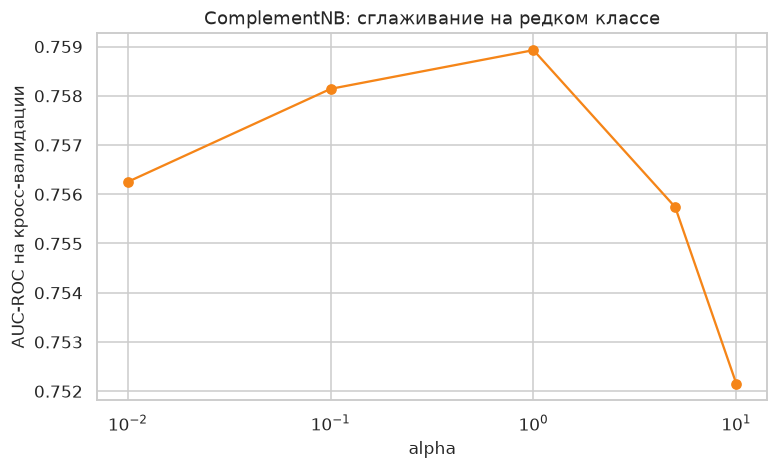

In [8]:
def make_complement(alpha=1.0):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("clf", ComplementNB(alpha=float(alpha))),
    ])


complement_df = remember(
    "ComplementNB", make_complement, multi_grid,
    {"alpha": 1.0},
    lambda kw: f"alpha={kw['alpha']:g}",
)
show_metrics(complement_df, ["alpha"])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
sub = complement_df.sort_values("alpha")
ax.plot(sub["alpha"], sub["roc_auc"], marker="o", color="#F58518")
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("AUC-ROC на кросс-валидации")
ax.set_title("ComplementNB: сглаживание на редком классе")
plt.tight_layout()
plt.show()

ComplementNB устроен так же по входу (неотрицательные признаки после MinMax), но оценивает дополнение класса. Для выборки, где отказов в восемь раз больше согласий, это более подходящая байесовская схема, чем обычный мультиномиальный классификатор: параметры редкого класса не тонут в массе отказов.

На двух классах ранжирование совпало с MultinomialNB: CV AUC на каждой точке `alpha` один и тот же, лучшая по правилу точка тоже `alpha = 5` и AUC 0,756. Отличается жёсткое решение. При том же alpha recall на кросс-валидации около 0,53 против 0,33 у обычного мультиномиального Байеса, accuracy ниже (0,84 против 0,89). ComplementNB чаще относит клиента к депозиту. Для обзвона это полезнее, чем одинаковый AUC.

### 5.4. BernoulliNB

ВЫБОР BernoulliNB: alpha=1, порог=0.5 | CV AUC 0.7682±0.0400 | F1 0.4660 | P 0.4067 | R 0.5487 | Acc 0.8628 | разрыв 0.0074 | база 0.7682 | прирост +0.0000


,alpha,threshold,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,0.1,0.25,0.7703,0.0338,0.4394,0.4195,0.4682,0.8713,0.7790
1,1.0,0.25,0.7694,0.0338,0.4406,0.4217,0.4682,0.8719,0.7775
2,0.1,0.50,0.7685,0.0403,0.4619,0.4023,0.5459,0.8613,0.7771
3,1.0,0.50,0.7682,0.0400,0.4660,0.4067,0.5487,0.8628,0.7756
4,10.0,0.50,0.7629,0.0398,0.4658,0.4199,0.5266,0.8686,0.7696
5,10.0,0.25,0.7613,0.0336,0.4248,0.4284,0.4295,0.8750,0.7687
6,1.0,0.75,0.7608,0.0391,0.4138,0.3397,0.5321,0.8343,0.7687
7,0.1,0.75,0.7605,0.0395,0.4117,0.3367,0.5320,0.8331,0.7700
8,10.0,0.75,0.7565,0.0395,0.4172,0.3756,0.4738,0.8568,0.7633


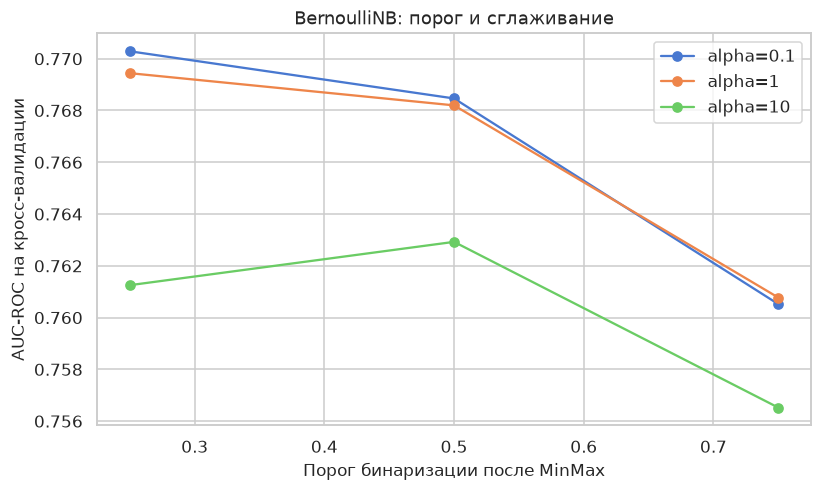

In [9]:
def make_bernoulli(alpha=1.0, threshold=0.5):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("clf", BernoulliNB(alpha=float(alpha), binarize=float(threshold))),
    ])


bernoulli_grid = [
    {"alpha": float(a), "threshold": float(t)}
    for a in (0.1, 1.0, 10.0)
    for t in (0.25, 0.5, 0.75)
]
bernoulli_df = remember(
    "BernoulliNB", make_bernoulli, bernoulli_grid,
    {"alpha": 1.0, "threshold": 0.5},
    lambda kw: f"alpha={kw['alpha']:g}, порог={kw['threshold']:g}",
)
show_metrics(bernoulli_df, ["alpha", "threshold"])

fig, ax = plt.subplots(figsize=(7.6, 4.6))
for alpha, sub in bernoulli_df.groupby("alpha"):
    sub = sub.sort_values("threshold")
    ax.plot(sub["threshold"], sub["roc_auc"], marker="o", label=f"alpha={alpha:g}")
ax.set_xlabel("Порог бинаризации после MinMax")
ax.set_ylabel("AUC-ROC на кросс-валидации")
ax.set_title("BernoulliNB: порог и сглаживание")
ax.legend()
plt.tight_layout()
plt.show()

После MinMax каждый признак лежит от 0 до 1. Порог 0,5 означает «значение выше середины своего диапазона». Для дамми это почти естественно: они и так равны 0 или 1, середина отделяет наличие категории. Для ставки и возраста порог выбрасывает величину отклонения и оставляет только «высокое / низкое». Если кривые при порогах 0,25, 0,5 и 0,75 почти совпадают, бинаризация грубая, но устойчивая. Если одна точка заметно выше, модели важно, где именно режется непрерывный признак.

`alpha` здесь играет ту же роль, что и у мультиномиального Байеса: не даёт редкой комбинации нулей и единиц получить нулевую вероятность. Все девять точек лежат в AUC 0,756–0,770. Порог 0,25 при `alpha = 0,1` чуть выше по AUC (0,770), но сильнее расходится с обучением, поэтому правило оставило заводские `alpha = 1` и порог 0,5: CV AUC 0,768, recall около 0,55, F1 0,466 — лучший F1 среди байесовских моделей на кросс-валидации. Бинаризация сигнал не уничтожила.

### 5.5. Дерево решений

ВЫБОР Дерево: depth=3, leaf=20, weight=None | CV AUC 0.7617±0.0348 | F1 0.3063 | P 0.6624 | R 0.2024 | Acc 0.9017 | разрыв 0.0115 | база 0.6069 | прирост +0.1548


,глубина,leaf,веса,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,4,20,balanced,0.7655,0.0404,0.4293,0.3448,0.5874,0.8279,0.7996
1,3,20,balanced,0.7621,0.0327,0.3958,0.3051,0.6177,0.7815,0.7814
2,3,20,без весов,0.7617,0.0348,0.3063,0.6624,0.2024,0.9017,0.7732
3,2,20,balanced,0.7545,0.0353,0.4731,0.4350,0.5210,0.8734,0.7634
4,4,20,без весов,0.7537,0.0440,0.2322,0.7528,0.1385,0.9008,0.7881
5,6,20,без весов,0.7523,0.0427,0.2819,0.5743,0.1885,0.8959,0.8259
6,3,1,balanced,0.7518,0.0357,0.4172,0.3537,0.5682,0.8167,0.7809
7,2,20,без весов,0.7500,0.0342,0.3063,0.6624,0.2024,0.9017,0.7566
8,2,1,balanced,0.7484,0.0374,0.4699,0.4334,0.5155,0.8731,0.7629
9,6,20,balanced,0.7478,0.0285,0.3810,0.2879,0.5819,0.7933,0.8300


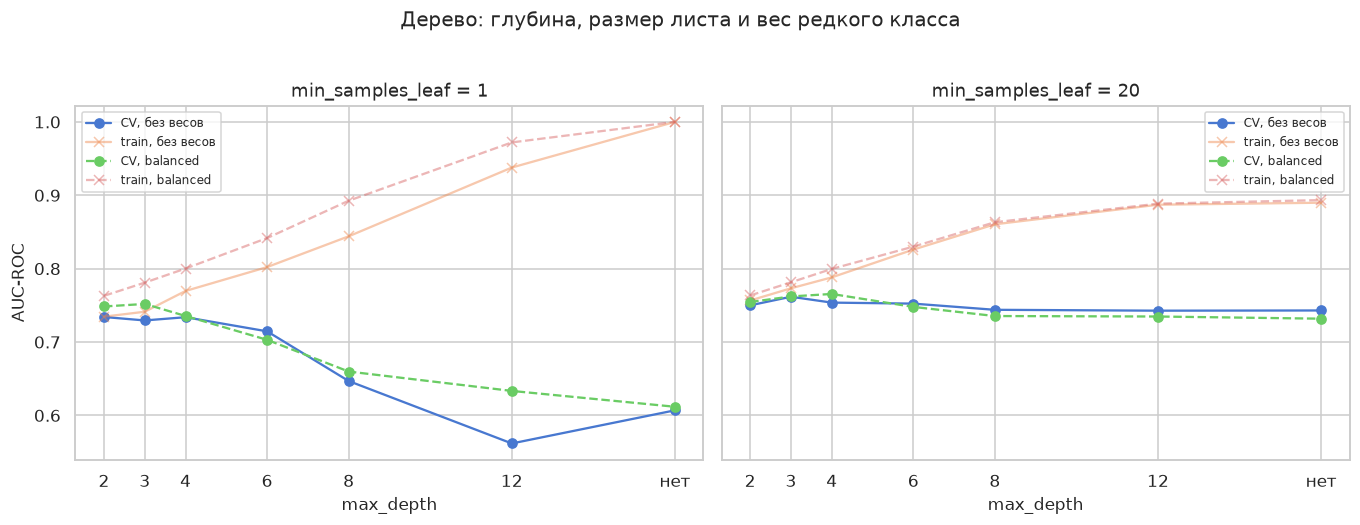

In [10]:
def make_tree(max_depth=None, min_samples_leaf=1, class_weight=None):
    return DecisionTreeClassifier(
        max_depth=None if max_depth is None else int(max_depth),
        min_samples_leaf=int(min_samples_leaf),
        class_weight=class_weight,
        criterion="gini",
        random_state=RANDOM_STATE,
    )


tree_grid = [
    {"max_depth": depth, "min_samples_leaf": leaf, "class_weight": weight}
    for depth in (2, 3, 4, 6, 8, 12, None)
    for leaf in (1, 20)
    for weight in (None, "balanced")
]
tree_df = remember(
    "Дерево", make_tree, tree_grid,
    {"max_depth": None, "min_samples_leaf": 1, "class_weight": None},
    lambda kw: f"depth={kw['max_depth']}, leaf={kw['min_samples_leaf']}, weight={kw['class_weight']}",
)
tree_view = tree_df.copy()
tree_view["глубина"] = ["нет" if kw["max_depth"] is None else str(int(kw["max_depth"])) for kw in tree_grid]
tree_view["leaf"] = [int(kw["min_samples_leaf"]) for kw in tree_grid]
tree_view["веса"] = ["balanced" if kw["class_weight"] == "balanced" else "без весов" for kw in tree_grid]
tree_view["x"] = [16 if kw["max_depth"] is None else int(kw["max_depth"]) for kw in tree_grid]
show_metrics(tree_view, ["глубина", "leaf", "веса"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, leaf in zip(axes, (1, 20)):
    for weight_name, style in (("без весов", "-"), ("balanced", "--")):
        sub = tree_view[(tree_view["leaf"] == leaf) & (tree_view["веса"] == weight_name)].sort_values("x")
        ax.plot(sub["x"], sub["roc_auc"], marker="o", ls=style, label=f"CV, {weight_name}")
        ax.plot(sub["x"], sub["roc_auc_train"], marker="x", ls=style, alpha=0.45, label=f"train, {weight_name}")
    ax.set_xticks([2, 3, 4, 6, 8, 12, 16])
    ax.set_xticklabels(["2", "3", "4", "6", "8", "12", "нет"])
    ax.set_xlabel("max_depth")
    ax.set_title(f"min_samples_leaf = {leaf}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("AUC-ROC")
fig.suptitle("Дерево: глубина, размер листа и вес редкого класса", y=1.03)
plt.tight_layout()
plt.show()

Неограниченное дерево с одним объектом в листе на обучении поднимает AUC почти до единицы: оно запоминает отдельных клиентов. На графике кружки — проверочный AUC, крестики — обучающий. Сплошная линия без весов классов, пунктир — `balanced`. Проверочная кривая растёт только на первых уровнях, дальше растёт разрыв между крестиками и кружками.

`min_samples_leaf = 20` запрещает листья из одного-двух человек. Неограниченное дерево с листом из одного клиента даёт обучающий AUC 1,000 и проверочный только 0,607. Ограничение `max_depth = 3` и `min_samples_leaf = 20` поднимает CV AUC до 0,762. Это самый большой прирост во всей работе, +0,155 к заводской настройке. `class_weight="balanced"` на этой глубине AUC почти не меняет, а recall увеличивает; правило оставило вариант без весов, у него меньше разрыв. Recall при этом около 0,20, precision около 0,66: дерево редко говорит «да».

### 5.6. Линейный дискриминантный анализ

ВЫБОР LDA: solver=lsqr, shrinkage=0.5, priors=по выборке | CV AUC 0.7707±0.0361 | F1 0.4178 | P 0.4830 | R 0.3713 | Acc 0.8877 | разрыв 0.0201 | база 0.7642 | прирост +0.0065


,solver,shrinkage,balanced_priors,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,lsqr,0.5,True,0.7726,0.0361,0.4117,0.3060,0.6318,0.8015,0.7958
1,lsqr,0.2,True,0.7723,0.0335,0.4198,0.3170,0.6235,0.8109,0.8039
2,lsqr,0.2,False,0.7718,0.0322,0.3976,0.4782,0.3435,0.8871,0.7985
3,lsqr,0.5,False,0.7707,0.0361,0.4178,0.4830,0.3713,0.8877,0.7908
4,lsqr,0.0,True,0.7684,0.0312,0.4325,0.3334,0.6180,0.8225,0.8080
5,lsqr,0.8,True,0.7655,0.0394,0.4001,0.2933,0.6318,0.7927,0.7812
6,svd,NaN,False,0.7642,0.0328,0.4449,0.5030,0.4017,0.8898,0.7984
7,svd,NaN,True,0.7642,0.0328,0.4820,0.4329,0.5460,0.8719,0.7984
8,lsqr,0.0,False,0.7642,0.0328,0.4449,0.5030,0.4017,0.8898,0.7984
9,lsqr,0.8,False,0.7638,0.0398,0.4280,0.4469,0.4156,0.8795,0.7772


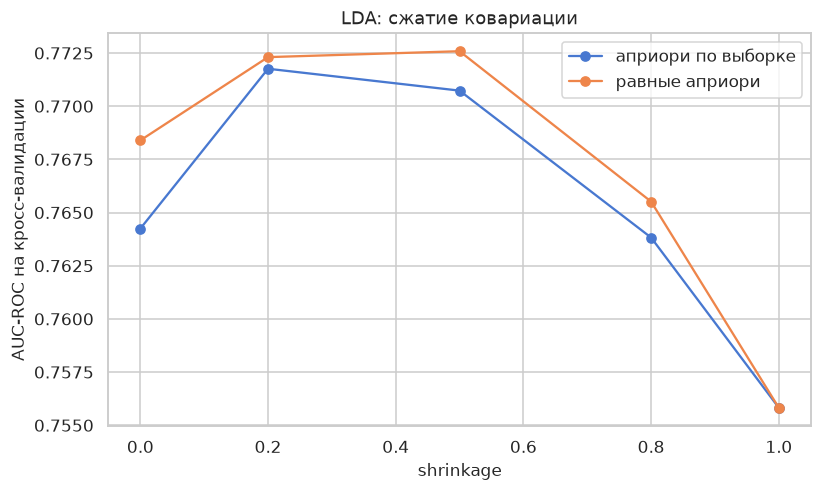

In [11]:
def make_lda(solver="svd", shrinkage=None, balanced_priors=False):
    priors = [0.5, 0.5] if balanced_priors else None
    if solver == "svd":
        clf = LinearDiscriminantAnalysis(solver="svd", priors=priors)
    else:
        clf = LinearDiscriminantAnalysis(solver="lsqr", shrinkage=float(shrinkage), priors=priors)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


lda_grid = [{"solver": "svd", "shrinkage": None, "balanced_priors": flag} for flag in (False, True)]
lda_grid += [
    {"solver": "lsqr", "shrinkage": float(s), "balanced_priors": flag}
    for s in (0.0, 0.2, 0.5, 0.8, 1.0)
    for flag in (False, True)
]
lda_df = remember(
    "LDA", make_lda, lda_grid,
    {"solver": "svd", "shrinkage": None, "balanced_priors": False},
    lambda kw: f"solver={kw['solver']}, shrinkage={kw['shrinkage']}, priors={'равные' if kw['balanced_priors'] else 'по выборке'}",
)
show_metrics(lda_df, ["solver", "shrinkage", "balanced_priors"])

lda_plot = lda_df[lda_df["_i"].map(lambda i: lda_grid[int(i)]["solver"]) == "lsqr"].copy()
lda_plot["shrinkage"] = lda_plot["_i"].map(lambda i: lda_grid[int(i)]["shrinkage"])
lda_plot["balanced_priors"] = lda_plot["_i"].map(lambda i: lda_grid[int(i)]["balanced_priors"])
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for flag, label in [(False, "априори по выборке"), (True, "равные априори")]:
    sub = lda_plot[lda_plot["balanced_priors"] == flag].sort_values("shrinkage")
    ax.plot(sub["shrinkage"], sub["roc_auc"], marker="o", label=label)
ax.set_xlabel("shrinkage")
ax.set_ylabel("AUC-ROC на кросс-валидации")
ax.set_title("LDA: сжатие ковариации")
ax.legend()
plt.tight_layout()
plt.show()

Обычный LDA (solver `svd`) оценивает полную ковариацию. Три макропоказателя коррелируют так сильно, что эта матрица плохо обусловлена: маленькие различия в занятости и в Euribor спорят за один и тот же эффект. `shrinkage` у решателя `lsqr` подмешивает к ковариации диагональную матрицу. Ноль — это обычная оценка, единица — признаки считаются некоррелированными, то есть LDA сближается с наивным Байесом по структуре зависимости.

Равные априорные вероятности [0,5, 0,5] заставляют границу не смотреть на то, что отказов больше. На сетке это почти не меняет AUC и поднимает recall примерно с 0,37 до 0,63. Выбрано другое: `solver=lsqr`, `shrinkage=0,5`, априори по выборке. CV AUC 0,771 против 0,764 у обычного `svd`, разрыв train-val 0,020. Сжатие ковариации здесь полезно именно потому, что Euribor, число занятых и изменение занятости описывают одну и ту же экономику.

### 5.7. Метод опорных векторов

ВЫБОР SVM: C=0.1, kernel=linear, gamma=scale, weight=balanced | CV AUC 0.7633±0.0369 | F1 0.4540 | P 0.3879 | R 0.5571 | Acc 0.8543 | разрыв 0.0280 | база 0.7296 | прирост +0.0336


,C,kernel,gamma,class_weight,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,0.1,rbf,0.01,balanced,0.7649,0.0377,0.4021,0.2930,0.6512,0.7848,0.8208
1,1.0,rbf,0.01,balanced,0.7649,0.0285,0.4645,0.3933,0.5709,0.8558,0.9030
2,0.1,linear,scale,balanced,0.7633,0.0369,0.4540,0.3879,0.5571,0.8543,0.7912
3,0.1,rbf,scale,balanced,0.7584,0.0350,0.4294,0.3255,0.6401,0.8121,0.8312
4,1.0,linear,scale,balanced,0.7574,0.0377,0.4423,0.3648,0.5736,0.8413,0.7860
5,10.0,linear,scale,balanced,0.7566,0.0374,0.4423,0.3648,0.5736,0.8413,0.7855
6,1.0,rbf,scale,balanced,0.7489,0.0311,0.4335,0.3657,0.5348,0.8467,0.9483
7,0.1,rbf,scale,без весов,0.7301,0.0126,0.0000,0.0000,0.0000,0.8904,0.9467
8,1.0,rbf,scale,без весов,0.7296,0.0087,0.2736,0.6257,0.1774,0.8980,0.9576
9,1.0,rbf,0.01,без весов,0.7202,0.0108,0.2985,0.6561,0.1968,0.9005,0.9202


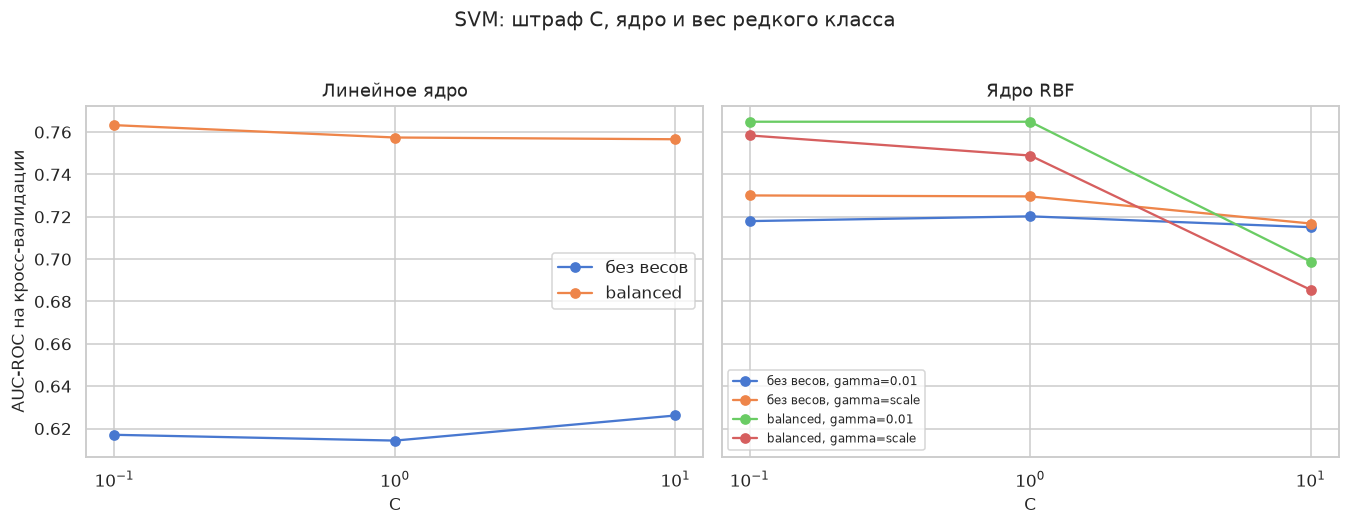

In [12]:
def make_svm(C=1.0, kernel="rbf", gamma="scale", class_weight=None):
    clf = SVC(
        C=float(C),
        kernel=kernel,
        gamma=gamma if kernel == "rbf" else "scale",
        class_weight=class_weight,
        random_state=RANDOM_STATE,
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


svm_grid = []
for C in (0.1, 1.0, 10.0):
    for weight in (None, "balanced"):
        svm_grid.append({"C": float(C), "kernel": "linear", "gamma": "scale", "class_weight": weight})
        for gamma in (0.01, "scale"):
            svm_grid.append({"C": float(C), "kernel": "rbf", "gamma": gamma, "class_weight": weight})

svm_df = remember(
    "SVM", make_svm, svm_grid,
    {"C": 1.0, "kernel": "rbf", "gamma": "scale", "class_weight": None},
    lambda kw: f"C={kw['C']:g}, kernel={kw['kernel']}, gamma={kw['gamma']}, weight={kw['class_weight']}",
)
svm_view = svm_df.copy()
svm_view["C"] = [float(kw["C"]) for kw in svm_grid]
svm_view["kernel"] = [kw["kernel"] for kw in svm_grid]
svm_view["gamma"] = [kw["gamma"] for kw in svm_grid]
svm_view["class_weight"] = ["balanced" if kw["class_weight"] == "balanced" else "без весов" for kw in svm_grid]
show_metrics(svm_view, ["C", "kernel", "gamma", "class_weight"])

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6), sharey=True)
linear = svm_view[svm_view["kernel"] == "linear"]
for weight_name in ("без весов", "balanced"):
    sub = linear[linear["class_weight"] == weight_name].sort_values("C")
    axes[0].plot(sub["C"], sub["roc_auc"], marker="o", label=weight_name)
axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_title("Линейное ядро")
axes[0].legend()
rbf = svm_view[svm_view["kernel"] == "rbf"]
for (weight_name, gamma), sub in rbf.groupby(["class_weight", "gamma"], sort=False):
    sub = sub.sort_values("C")
    axes[1].plot(sub["C"], sub["roc_auc"], marker="o", label=f"{weight_name}, gamma={gamma}")
axes[1].set_xscale("log")
axes[1].set_xlabel("C")
axes[1].set_title("Ядро RBF")
axes[1].legend(fontsize=8)
axes[0].set_ylabel("AUC-ROC на кросс-валидации")
fig.suptitle("SVM: штраф C, ядро и вес редкого класса", y=1.03)
plt.tight_layout()
plt.show()

Параметр `C` — плата за ошибку на обучении. Маленький `C` даёт широкую границу и игнорирует часть клиентов у края. Большой `C` подтягивает границу к каждому обучению, и для RBF это уже риск запомнить шум.

Линейное ядро может только отделить классы гиперплоскостью. Если оно близко к RBF по AUC, зависимость в этих признаках в основном линейная, и более гибкое ядро не окупается. `gamma` у RBF задаёт, насколько далеко тянется влияние одного клиента: маленькая gamma — гладкая граница, `scale` — ширина по дисперсии признаков.

`class_weight="balanced"` сдвигает зазор в пользу класса «да». Заводское RBF без весов даёт CV AUC только 0,730 и на части сетки нулевой recall: граница относит почти всех к отказу. Выбрано линейное ядро, `C = 0,1` и веса классов: CV AUC 0,763, recall 0,557, прирост к заводской настройке +0,034. Большой `C` у RBF задирает обучающий AUC к 0,99 и портит проверку. Гибкое ядро на этих признаках не лучше гиперплоскости.

### 5.8. Метод k ближайших соседей

ВЫБОР kNN: k=41, weights=uniform | CV AUC 0.7499±0.0447 | F1 0.2398 | P 0.6378 | R 0.1497 | Acc 0.8974 | разрыв 0.0669 | база 0.7067 | прирост +0.0432


,n_neighbors,weights,roc_auc,roc_auc_std,f1,precision,recall,accuracy,roc_auc_train
0,41,distance,0.7517,0.0460,0.2614,0.6418,0.1664,0.8983,1.0000
1,41,uniform,0.7499,0.0447,0.2398,0.6378,0.1497,0.8974,0.8168
2,25,distance,0.7462,0.0406,0.2900,0.6492,0.1885,0.8998,1.0000
3,25,uniform,0.7441,0.0405,0.2918,0.6736,0.1885,0.9011,0.8316
4,15,distance,0.7381,0.0367,0.2942,0.5738,0.1995,0.8959,1.0000
5,15,uniform,0.7374,0.0325,0.2844,0.5927,0.1884,0.8968,0.8592
6,9,distance,0.7310,0.0386,0.3275,0.5563,0.2328,0.8956,1.0000
7,9,uniform,0.7302,0.0355,0.3354,0.5844,0.2355,0.8980,0.8897
8,5,distance,0.7070,0.0285,0.3339,0.5018,0.2522,0.8910,1.0000
9,5,uniform,0.7067,0.0257,0.3470,0.5519,0.2549,0.8962,0.9196


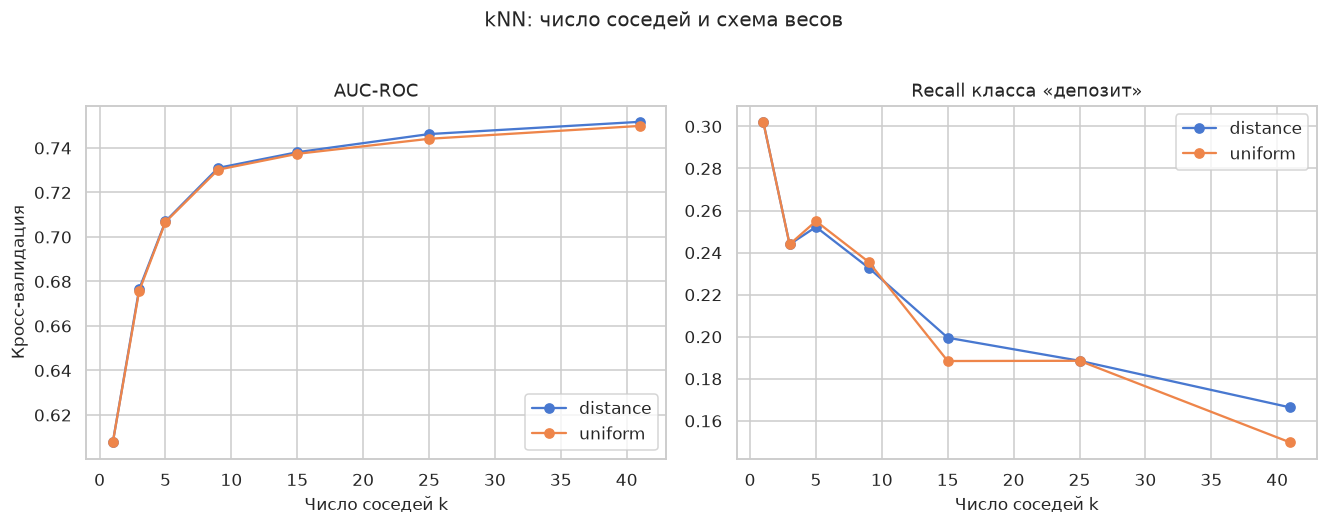

In [13]:
def make_knn(n_neighbors=5, weights="uniform"):
    clf = KNeighborsClassifier(n_neighbors=int(n_neighbors), weights=weights, metric="euclidean")
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


knn_grid = [
    {"n_neighbors": k, "weights": w}
    for k in (1, 3, 5, 9, 15, 25, 41)
    for w in ("uniform", "distance")
]
knn_df = remember(
    "kNN", make_knn, knn_grid,
    {"n_neighbors": 5, "weights": "uniform"},
    lambda kw: f"k={kw['n_neighbors']}, weights={kw['weights']}",
)
knn_view = knn_df.copy()
knn_view["n_neighbors"] = knn_view["_i"].map(lambda i: knn_grid[int(i)]["n_neighbors"])
knn_view["weights"] = knn_view["_i"].map(lambda i: knn_grid[int(i)]["weights"])
show_metrics(knn_view, ["n_neighbors", "weights"])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
for weights, sub in knn_view.groupby("weights"):
    sub = sub.sort_values("n_neighbors")
    axes[0].plot(sub["n_neighbors"], sub["roc_auc"], marker="o", label=weights)
    axes[1].plot(sub["n_neighbors"], sub["recall"], marker="o", label=weights)
axes[0].set_title("AUC-ROC")
axes[1].set_title("Recall класса «депозит»")
for ax in axes:
    ax.set_xlabel("Число соседей k")
    ax.legend()
axes[0].set_ylabel("Кросс-валидация")
fig.suptitle("kNN: число соседей и схема весов", y=1.03)
plt.tight_layout()
plt.show()

При k = 1 сосед один. Обучающий AUC равен 1, проверочный — только 0,608. К k = 41 проверочный AUC вырастает до 0,750, это выбранная точка (`weights="uniform"`), прирост к заводским пяти соседям +0,043. Recall при этом падает до 0,15: среди 41 соседа почти всегда большинство отказов. `weights="distance"` тоже запоминает обучение (AUC 1,000) и по правилу отсева не выбран. Правая панель это показывает отдельно от AUC. На этих данных соседи слабее линейной границы.

### 5.9. Сводка настройки

,Метод,По умолчанию,AUC по умолчанию,Выбрано,AUC после выбора,Прирост AUC,F1 CV,Recall CV,Разрыв train-val
0,LDA,"solver=svd, shrinkage=None, priors=по выборке",0.7642,"solver=lsqr, shrinkage=0.5, priors=по выборке",0.7707,0.0065,0.4178,0.3713,0.0201
1,BernoulliNB,"alpha=1, порог=0.5",0.7682,"alpha=1, порог=0.5",0.7682,0.0000,0.4660,0.5487,0.0074
2,GaussianNB,"var_smoothing=1e-09, scale=True",0.7502,"var_smoothing=1e-03, scale=False",0.7633,0.0131,0.4449,0.4350,0.0004
3,SVM,"C=1, kernel=rbf, gamma=scale, weight=None",0.7296,"C=0.1, kernel=linear, gamma=scale, weight=bala...",0.7633,0.0336,0.4540,0.5571,0.0280
4,Дерево,"depth=None, leaf=1, weight=None",0.6069,"depth=3, leaf=20, weight=None",0.7617,0.1548,0.3063,0.2024,0.0115
5,MultinomialNB,alpha=1,0.7589,alpha=5,0.7557,-0.0032,0.4015,0.3326,0.0109
6,ComplementNB,alpha=1,0.7589,alpha=5,0.7557,-0.0032,0.4177,0.5265,0.0109
7,kNN,"k=5, weights=uniform",0.7067,"k=41, weights=uniform",0.7499,0.0432,0.2398,0.1497,0.0669


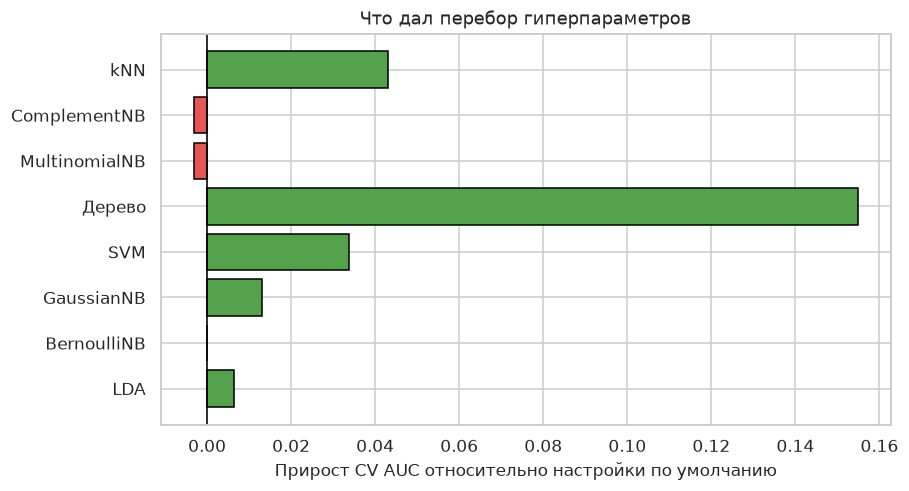

In [14]:
tuning = pd.DataFrame(TUNING_ROWS).sort_values("AUC после выбора", ascending=False).reset_index(drop=True)
display(tuning.round(4))

fig, ax = plt.subplots(figsize=(8.4, 4.6))
colors = ["#54A24B" if value >= 0 else "#E45756" for value in tuning["Прирост AUC"]]
ax.barh(tuning["Метод"], tuning["Прирост AUC"], color=colors, edgecolor="black")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Прирост CV AUC относительно настройки по умолчанию")
ax.set_title("Что дал перебор гиперпараметров")
plt.tight_layout()
plt.show()

Прирост на диаграмме — это не качество на тесте, а польза перебора относительно заводской настройки на кросс-валидации. Сильнее всего он помог дереву (+0,155) и kNN (+0,043): заводские настройки там запоминали выборку. SVM прибавил 0,034 за счёт весов редкого класса и линейного ядра. LDA прибавил 0,007 от shrinkage. BernoulliNB не нашёл ничего лучше `alpha = 1` и порога 0,5. У MultinomialNB и ComplementNB выбранная точка на 0,003 ниже заводской: правило отдало эту мелочь за меньший разрыв обучения и проверки.

Дальше на тест попадает ровно одна модель каждого семейства — та, что в столбце «Выбрано». Подбирать параметры заново по тестовой таблице нельзя.

## 6. Сравнительный анализ классических методов

Метрики ниже посчитаны один раз на отложенных 20% клиентов. Вероятностные модели режутся порогом 0,5. У SVM непрерывная оценка — отступ `decision_function`, жёсткая метка — его знак. Для ROC используется непрерывная оценка, поэтому площадь под кривой не обязана согласовываться с recall при стандартном пороге.

,Метод,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,LDA,0.8993,0.5686,0.3222,0.4113,0.7784
1,BernoulliNB,0.8750,0.4393,0.5222,0.4772,0.7748
2,ComplementNB,0.8532,0.3817,0.5556,0.4525,0.7728
3,MultinomialNB,0.9041,0.6410,0.2778,0.3876,0.7728
4,GaussianNB,0.8896,0.4925,0.3667,0.4204,0.7698
5,Дерево,0.9029,0.8125,0.1444,0.2453,0.7655
6,SVM,0.8422,0.3611,0.5778,0.4444,0.7620
7,kNN,0.9005,0.7500,0.1333,0.2264,0.7387
8,Всегда отказ,0.8908,0.0000,0.0000,0.0000,0.5000


Лучший AUC на тесте: LDA | AUC 0.7784 | F1 0.4113 | P 0.5686 | R 0.3222 | Acc 0.8993


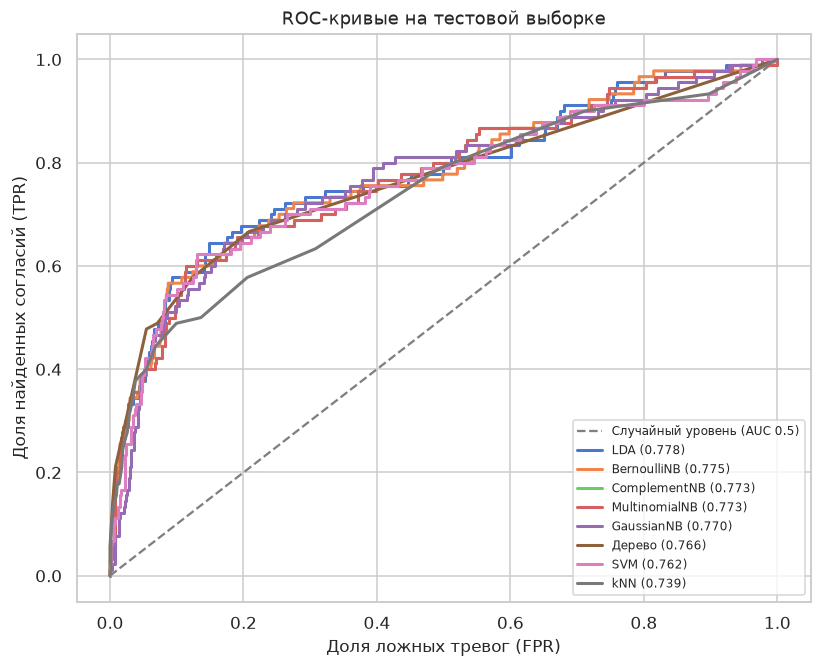

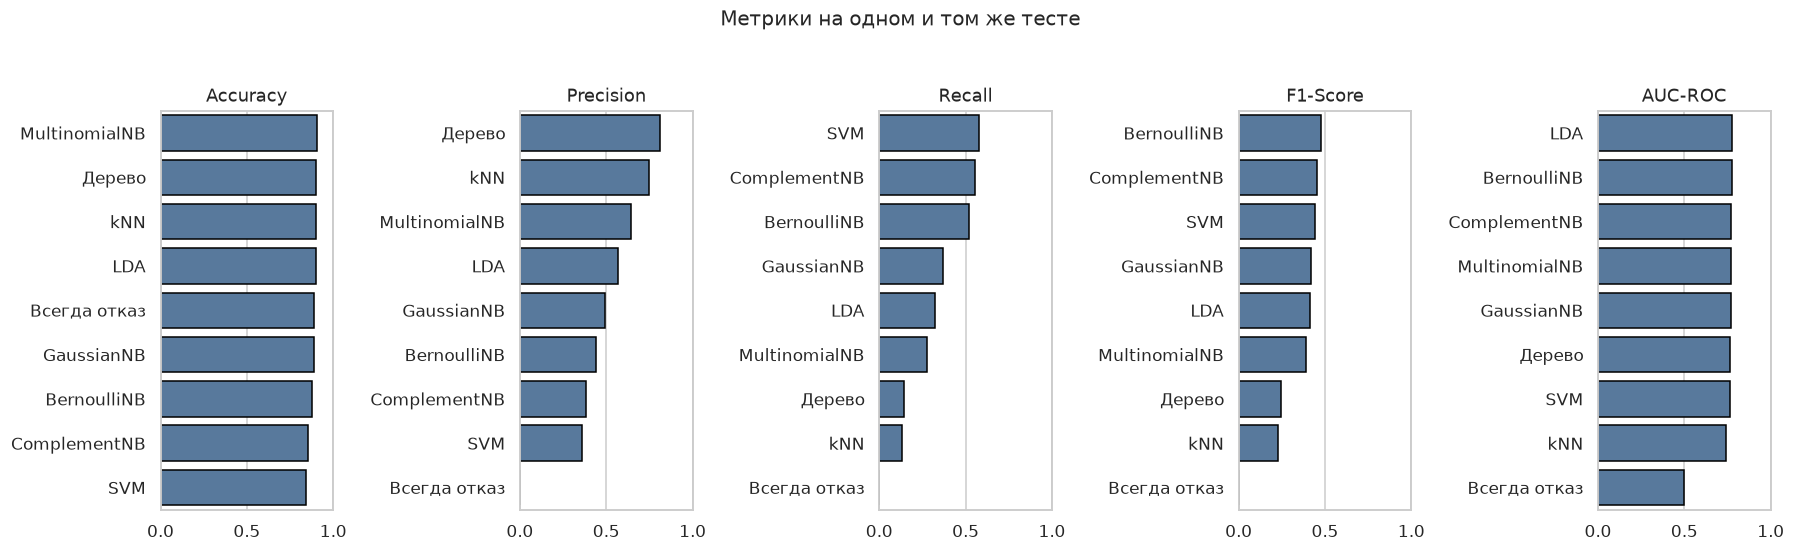

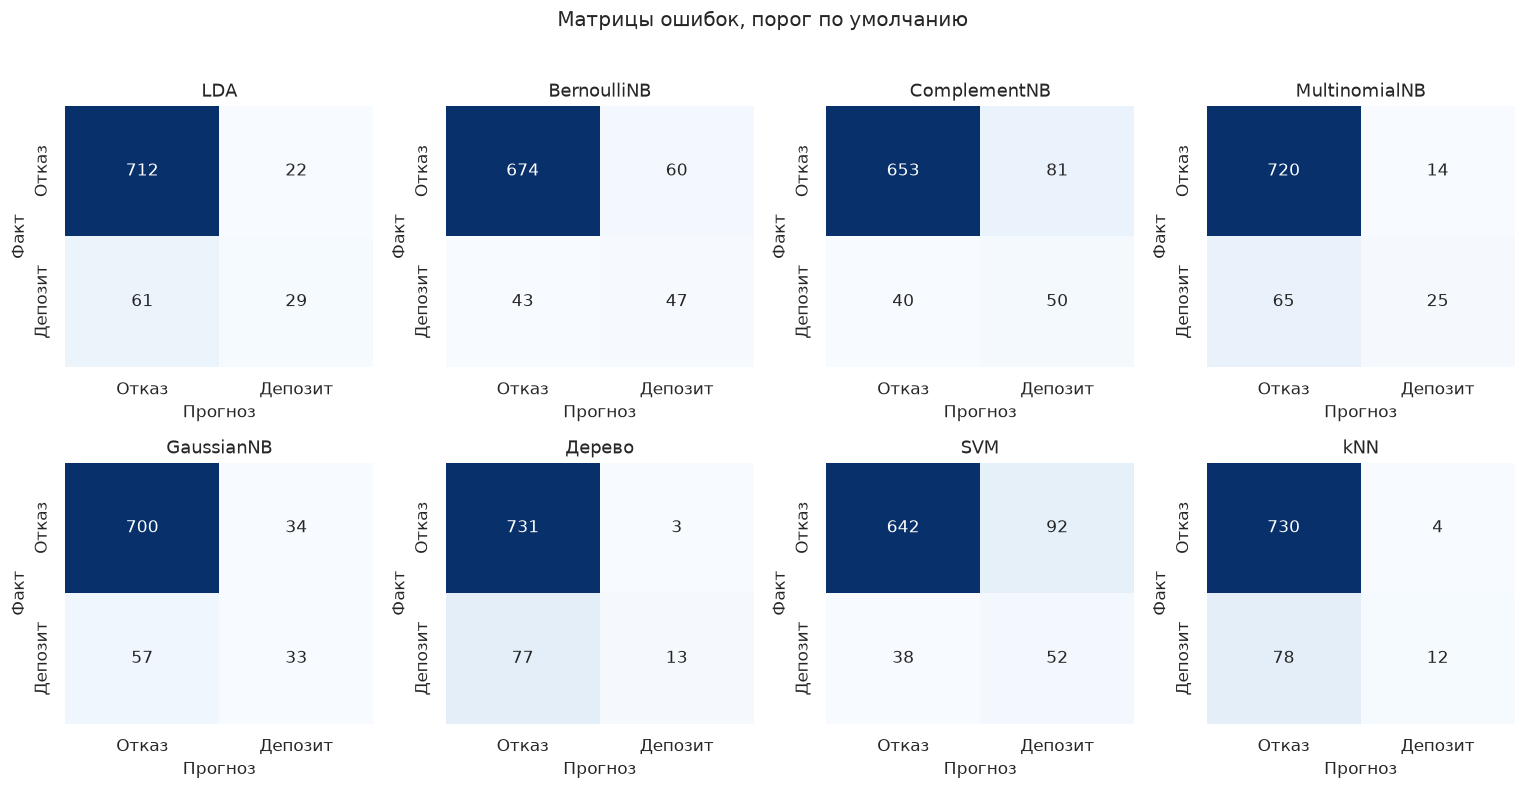

In [15]:
def positive_score(model, features):
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(features)
        if proba.ndim == 2 and proba.shape[1] == 2:
            return proba[:, 1]
    return np.asarray(model.decision_function(features)).ravel()


def test_metrics(name, y_true, y_pred, y_score):
    return {
        "Метод": name,
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "F1-Score": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "AUC-ROC": float(roc_auc_score(y_true, y_score)),
    }


y_true = y_test.to_numpy().astype(int)
rows = [{
    "Метод": "Всегда отказ",
    "Accuracy": float((y_true == 0).mean()),
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-Score": 0.0,
    "AUC-ROC": 0.5,
}]
SCORES = {}
PREDS = {}
for name, payload in CHOSEN.items():
    model = payload["model"]
    pred = model.predict(X_test).astype(int)
    score = positive_score(model, X_test)
    rows.append(test_metrics(name, y_true, pred, score))
    SCORES[name] = score
    PREDS[name] = pred

report = pd.DataFrame(rows).sort_values(["AUC-ROC", "F1-Score", "Recall"], ascending=False).reset_index(drop=True)
display(report.round(4))
leader = report[report["Метод"] != "Всегда отказ"].iloc[0]
print(
    f"Лучший AUC на тесте: {leader['Метод']} | "
    f"AUC {leader['AUC-ROC']:.4f} | F1 {leader['F1-Score']:.4f} | "
    f"P {leader['Precision']:.4f} | R {leader['Recall']:.4f} | Acc {leader['Accuracy']:.4f}"
)

fig, ax = plt.subplots(figsize=(7.6, 6.2))
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Случайный уровень (AUC 0.5)")
for _, row in report[report["Метод"] != "Всегда отказ"].iterrows():
    fpr, tpr, _ = roc_curve(y_true, SCORES[row["Метод"]])
    ax.plot(fpr, tpr, lw=2, label=f"{row['Метод']} ({row['AUC-ROC']:.3f})")
ax.set_xlabel("Доля ложных тревог (FPR)")
ax.set_ylabel("Доля найденных согласий (TPR)")
ax.set_title("ROC-кривые на тестовой выборке")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
plot_df = report.melt(id_vars="Метод", value_vars=metric_names, var_name="Метрика", value_name="Значение")
fig, axes = plt.subplots(1, 5, figsize=(16.5, 4.8), sharey=False)
for ax, metric in zip(axes, metric_names):
    sub = plot_df[plot_df["Метрика"] == metric].sort_values("Значение", ascending=False)
    sns.barplot(data=sub, y="Метод", x="Значение", ax=ax, color="#4C78A8", edgecolor="black")
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
fig.suptitle("Метрики на одном и том же тесте", y=1.04)
plt.tight_layout()
plt.show()

names = [name for name in report["Метод"] if name != "Всегда отказ"]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, name in zip(axes.ravel(), names):
    matrix = confusion_matrix(y_true, PREDS[name], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Отказ", "Депозит"], yticklabels=["Отказ", "Депозит"])
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Факт")
    ax.set_title(name)
fig.suptitle("Матрицы ошибок, порог по умолчанию", y=1.02)
plt.tight_layout()
plt.show()

Столбцы accuracy легко прочитать неправильно. Константа «всегда отказ» стоит в таблице специально: у неё accuracy около 0,89, а депозит она не находит ни разу. Модель, которая чуть аккуратнее константы, но имеет recall, близкий к нулю, просто почти всегда говорит «нет» и изредка угадывает.

ROC-кривая отвечает на другой вопрос: если отсортировать клиентов по оценке модели и обзванивать сверху вниз, будет ли среди первых много тех, кто согласится. Кривая выше диагонали означает, что такое упорядочивание лучше случайного. Площадь под ней и есть AUC. Модель с высоким AUC и скромным recall при пороге 0,5 не провалилась: стандартный порог для редкого класса слишком жёсткий, а ранжирование уже годится, чтобы выбрать, кому звонить в первую очередь.

Precision в этой задаче — доля напрасных звонков среди тех, кого модель назвала перспективными. Recall — доля согласившихся, которых модель пропустила мимо. F1 наказывает модель, которая вытягивает одну из этих двух величин за счёт обнуления другой. Матрицы ошибок показывают то же самое в людях, а не в долях: клетка «факт депозит / прогноз отказ» — это потерянные клиенты.

Лучший AUC на тесте у LDA: 0,778 при accuracy 0,899, precision 0,569, recall 0,322 и F1 0,411. До константы 0,891 по accuracy ему один шаг, но константа не находит ни одного из 90 согласившихся, а LDA находит около трети.

Лучший F1 у BernoulliNB: 0,477 при recall 0,522, precision 0,439 и AUC 0,775. ComplementNB и линейный SVM с весами находят ещё немного больше согласий (recall 0,556 и 0,578). У SVM accuracy 0,842, это ниже константы. Так и должно читаться: accuracy наказывает модель, которая пытается искать редкий класс.

Дерево глубины 3, когда говорит «да», чаще всего право (precision 0,813), но находит только 14% согласий. kNN с 41 соседом похож на него и имеет худший AUC среди рабочих моделей, 0,739. MultinomialNB и ComplementNB снова совпали по AUC 0,773 и разошлись по порогу: recall 0,278 против 0,556.

Для ранжирования «кому звонить сначала» достаточно LDA: у него лучшая ROC-кривая, порог 0,5 можно сдвинуть отдельно. Если нужен готовый список согласий при стандартном пороге, практичнее BernoulliNB, ComplementNB или SVM с весами. Ориентир для сети — LDA.

## 7. Нейронная сеть на TensorFlow

Сеть — обычный многослойный перцептрон. На входе те же признаки, что и у SVM. Скрытые слои уменьшают ширину вдвое, но не уже 8 нейронов. После первого скрытого слоя стоит dropout. Выход — один нейрон с сигмоидой: это оценка вероятности депозита. Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam.

Подбор идёт жадно и только по проверочной части обучения (20% обучающей выборки, тоже со стратификацией). Тест здесь не используется. Порядок такой: скорость обучения, ширина первого слоя, число скрытых слоёв, функция активации, размер батча, число эпох, dropout. На каждом шаге оставляется вариант, у которого проверочный AUC не хуже лучшего более чем на 0,005, а validation loss меньше. Accuracy на этом шаге не используется как критерий: при 11% согласий сеть, которая всем предсказывает отказ, получает accuracy около 0,89.

Во время каждого прогона Keras пишет loss и accuracy обучения и проверки в журнал TensorBoard. Графики ниже читаются из этих event-файлов. Открыть тот же журнал отдельно можно командой `tensorboard --logdir logs/tensorboard` из папки лабораторной: в браузере будут те же четыре кривые.

Веса классов включены уже на подборе. Иначе редкий класс почти не двигает кросс-энтропию, и сеть учится говорить «нет».

Веса классов на подборе: {0: 0.562, 1: 4.561}
Журнал TensorBoard: D:\sharaga\AIslop\Lab2_Classification\logs\tensorboard
Вход сети: 53 признаков


L2_U32_relu_lr1e-04_d0.2_bs32_ep25: val AUC 0.7684 | val loss 0.5288 | val recall 0.5833 | источник кривых TensorBoard


L2_U32_relu_lr1e-03_d0.2_bs32_ep25: val AUC 0.7431 | val loss 0.4436 | val recall 0.5278 | источник кривых TensorBoard


L2_U32_relu_lr1e-02_d0.2_bs32_ep25: val AUC 0.7330 | val loss 0.4884 | val recall 0.4444 | источник кривых TensorBoard


,learning_rate,val AUC,val loss,val recall,val F1,эпоха min val loss
0,0.0001,0.7684,0.5288,0.5833,0.4200,25
1,0.0010,0.7431,0.4436,0.5278,0.4270,25
2,0.0100,0.7330,0.4884,0.4444,0.3787,15


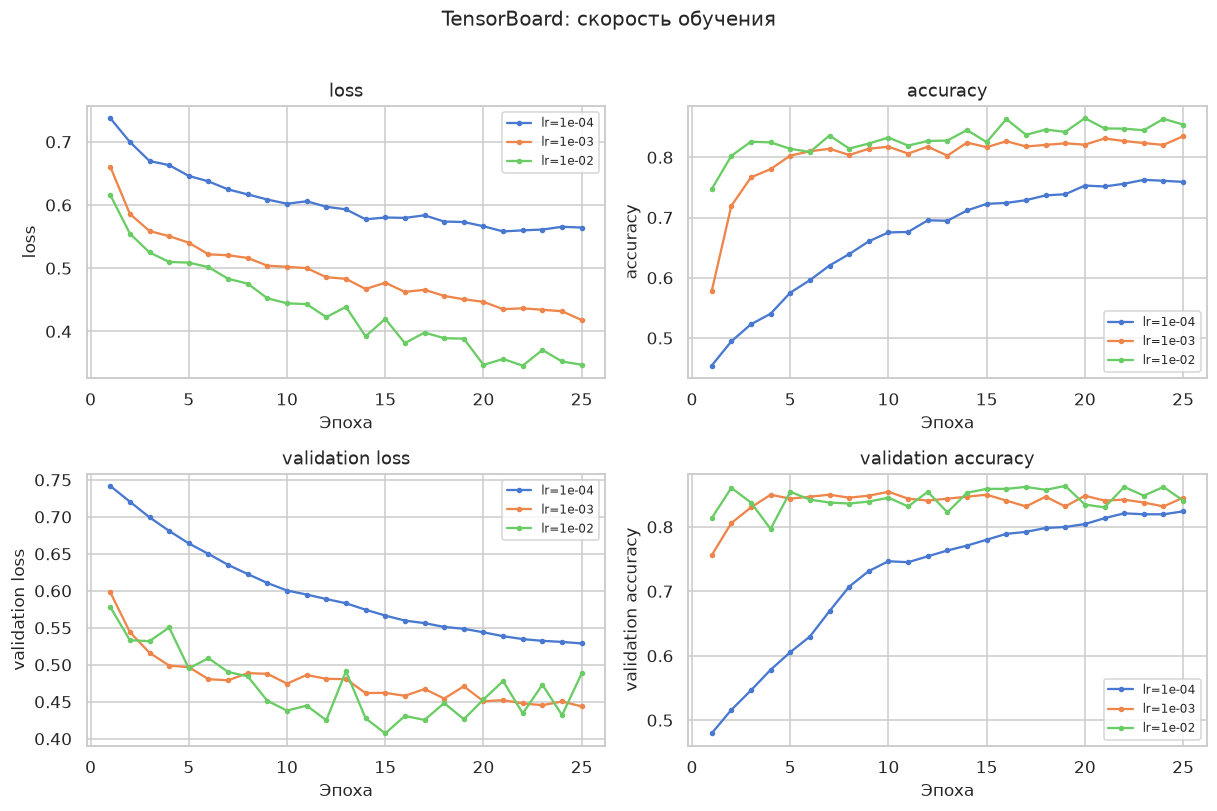

Оставлен learning_rate = 0.0001


L2_U16_relu_lr1e-04_d0.2_bs32_ep25: val AUC 0.7309 | val loss 0.7105 | val recall 0.7500 | источник кривых TensorBoard


L2_U64_relu_lr1e-04_d0.2_bs32_ep25: val AUC 0.7734 | val loss 0.5032 | val recall 0.6111 | источник кривых TensorBoard


,units,val AUC,val loss,val recall,val F1,эпоха min val loss
0,16,0.7309,0.7105,0.7500,0.2714,25
1,32,0.7684,0.5288,0.5833,0.4200,25
2,64,0.7734,0.5032,0.6111,0.4467,25


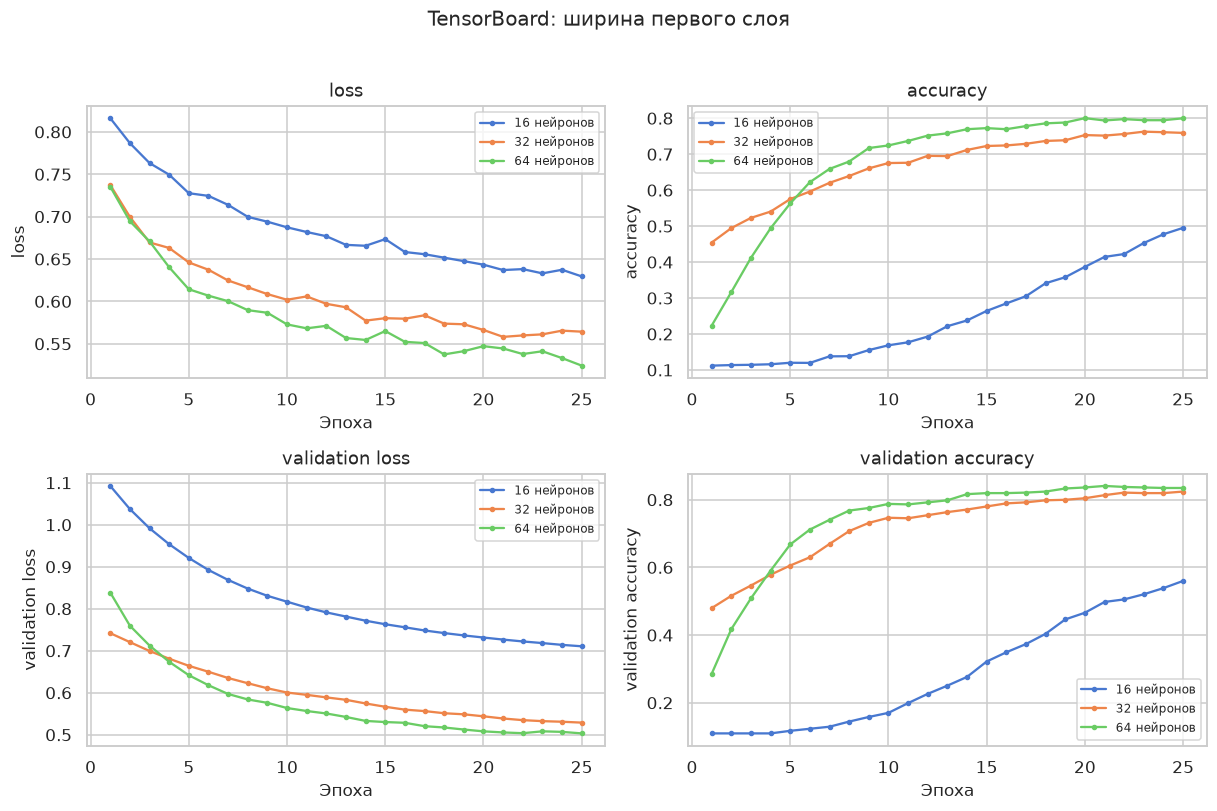

Оставлен units = 64


L1_U64_relu_lr1e-04_d0.2_bs32_ep25: val AUC 0.7898 | val loss 0.5144 | val recall 0.6528 | источник кривых TensorBoard


L3_U64_relu_lr1e-04_d0.2_bs32_ep25: val AUC 0.7697 | val loss 0.5008 | val recall 0.5972 | источник кривых TensorBoard


,n_layers,val AUC,val loss,val recall,val F1,эпоха min val loss
0,1,0.7898,0.5144,0.6528,0.4563,25
1,2,0.7734,0.5032,0.6111,0.4467,25
2,3,0.7697,0.5008,0.5972,0.4479,22


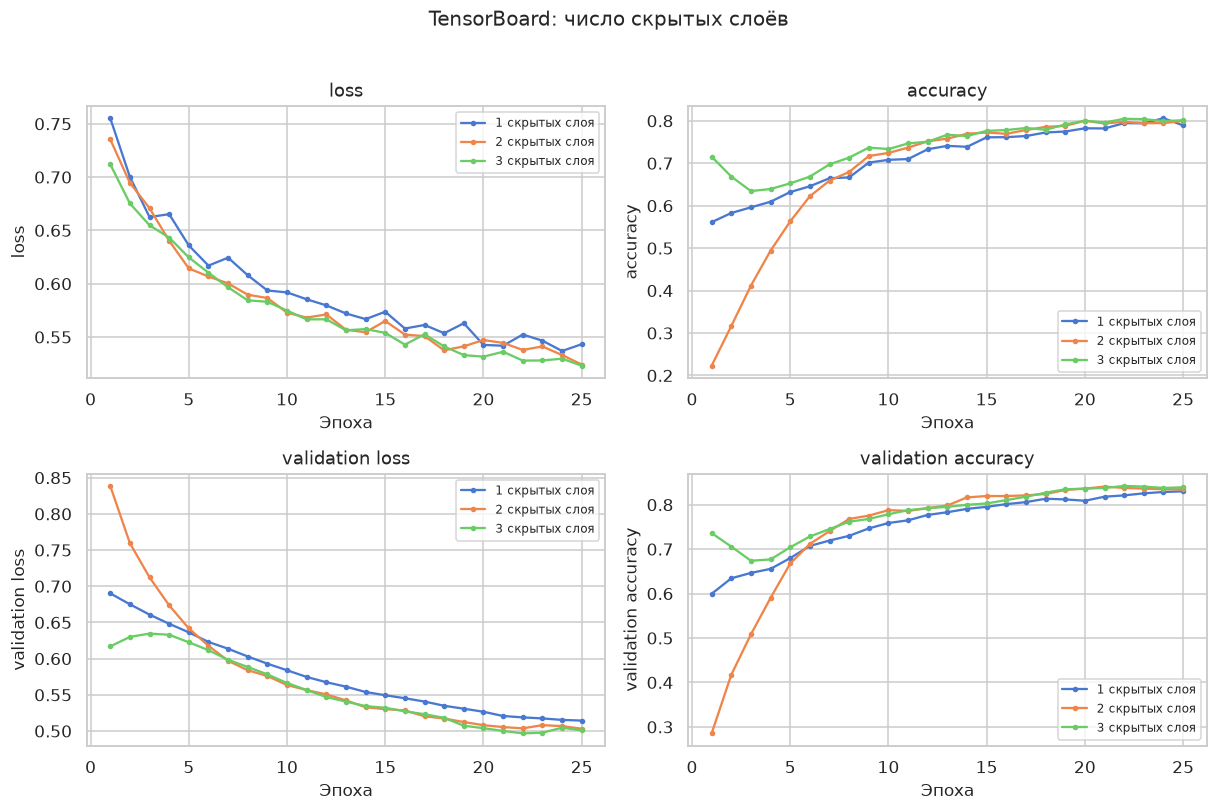

Оставлен n_layers = 1


L1_U64_tanh_lr1e-04_d0.2_bs32_ep25: val AUC 0.7740 | val loss 0.5217 | val recall 0.6111 | источник кривых TensorBoard


,activation,val AUC,val loss,val recall,val F1,эпоха min val loss
0,relu,0.7898,0.5144,0.6528,0.4563,25
1,tanh,0.7740,0.5217,0.6111,0.4422,25


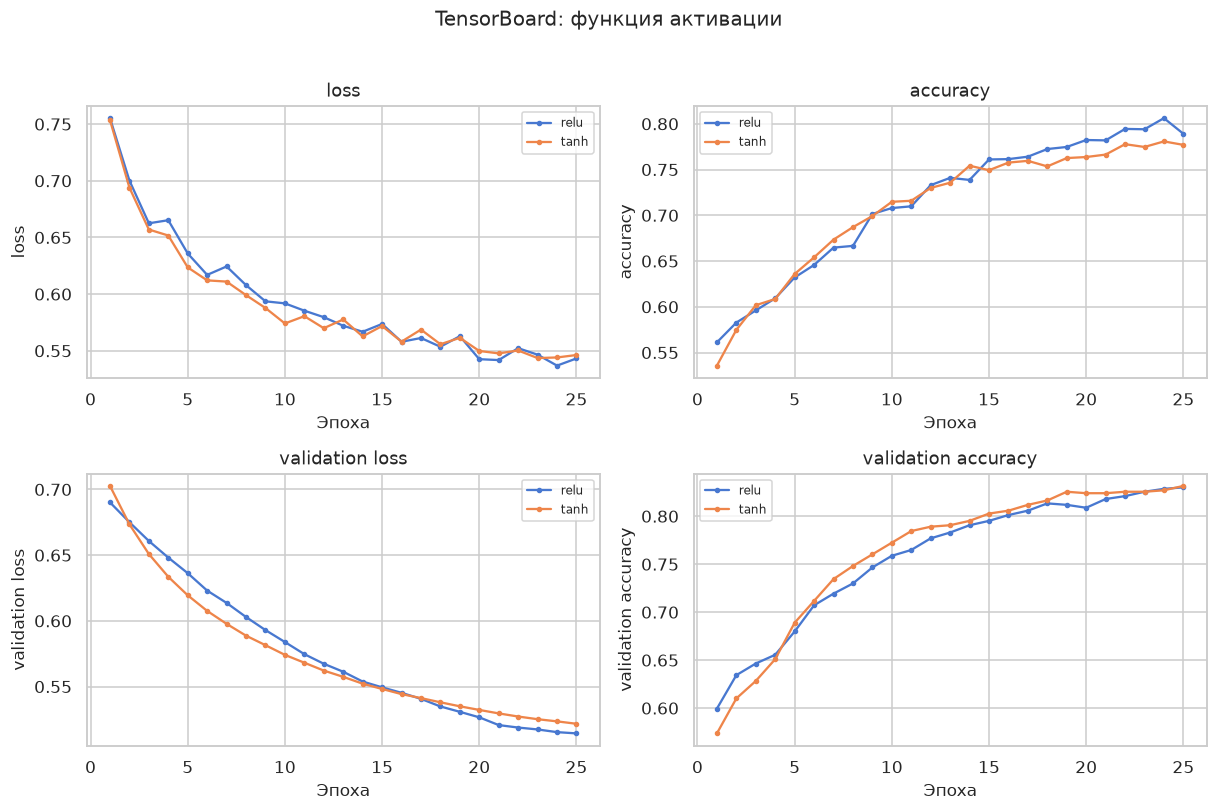

Оставлен activation = relu


L1_U64_relu_lr1e-04_d0.2_bs16_ep25: val AUC 0.7901 | val loss 0.5003 | val recall 0.6389 | источник кривых TensorBoard


L1_U64_relu_lr1e-04_d0.2_bs128_ep25: val AUC 0.7634 | val loss 0.5756 | val recall 0.6944 | источник кривых TensorBoard


,batch_size,val AUC,val loss,val recall,val F1,эпоха min val loss
0,16,0.7901,0.5003,0.6389,0.4577,25
1,32,0.7898,0.5144,0.6528,0.4563,25
2,128,0.7634,0.5756,0.6944,0.3922,25


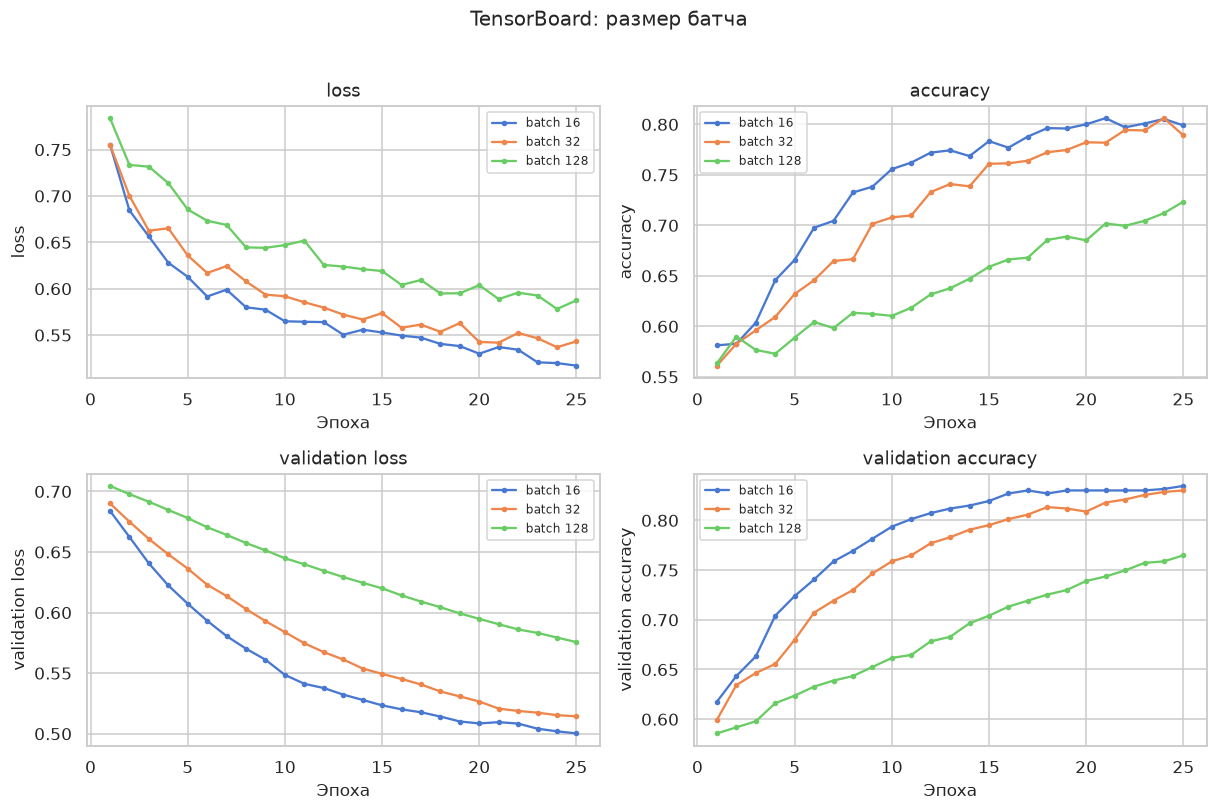

Оставлен batch_size = 16


L1_U64_relu_lr1e-04_d0.2_bs16_ep10: val AUC 0.7773 | val loss 0.5485 | val recall 0.6806 | источник кривых TensorBoard


L1_U64_relu_lr1e-04_d0.2_bs16_ep40: val AUC 0.7911 | val loss 0.4851 | val recall 0.6111 | источник кривых TensorBoard


,epochs,val AUC,val loss,val recall,val F1,эпоха min val loss
0,10,0.7773,0.5485,0.6806,0.4188,10
1,25,0.7901,0.5003,0.6389,0.4577,25
2,40,0.7911,0.4851,0.6111,0.4536,39


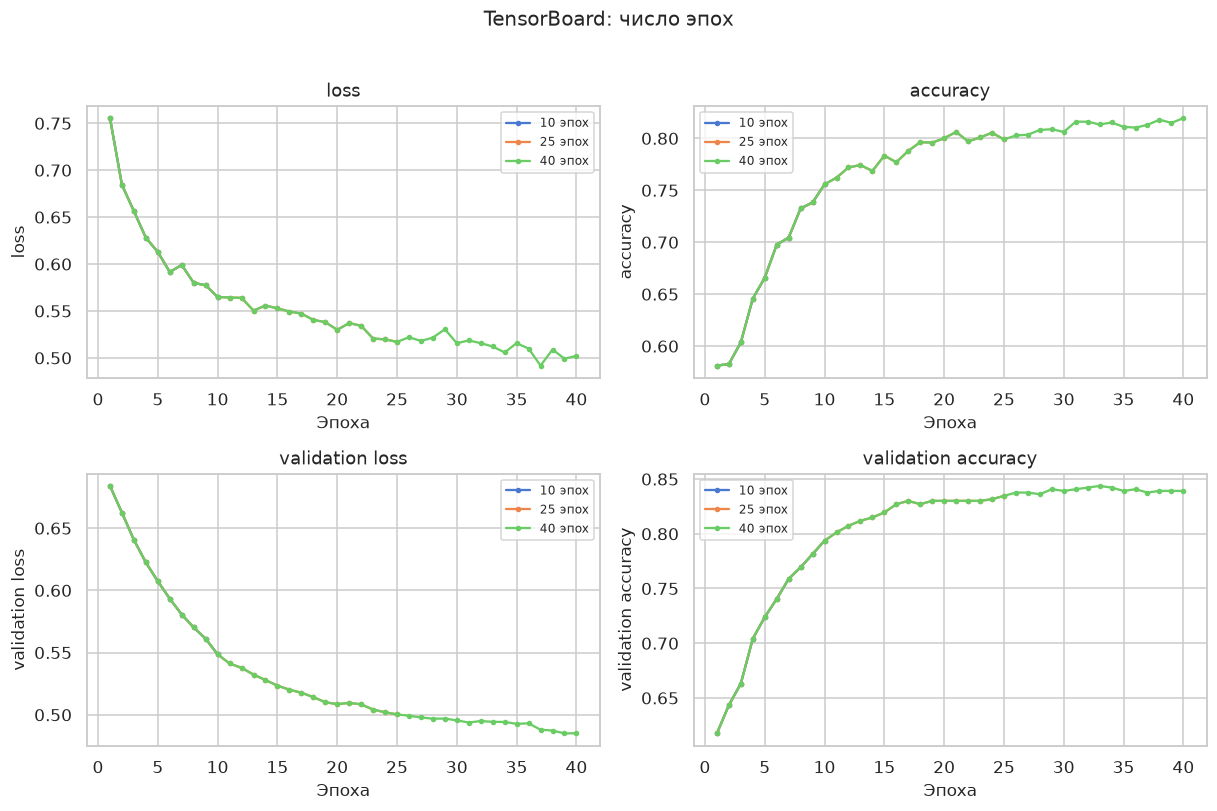

Оставлен epochs = 40


L1_U64_relu_lr1e-04_d0.0_bs16_ep40: val AUC 0.7804 | val loss 0.4731 | val recall 0.5972 | источник кривых TensorBoard


L1_U64_relu_lr1e-04_d0.5_bs16_ep40: val AUC 0.7924 | val loss 0.5003 | val recall 0.6389 | источник кривых TensorBoard


,dropout,val AUC,val loss,val recall,val F1,эпоха min val loss
0,0.0,0.7804,0.4731,0.5972,0.4456,40
1,0.2,0.7911,0.4851,0.6111,0.4536,39
2,0.5,0.7924,0.5003,0.6389,0.4670,39


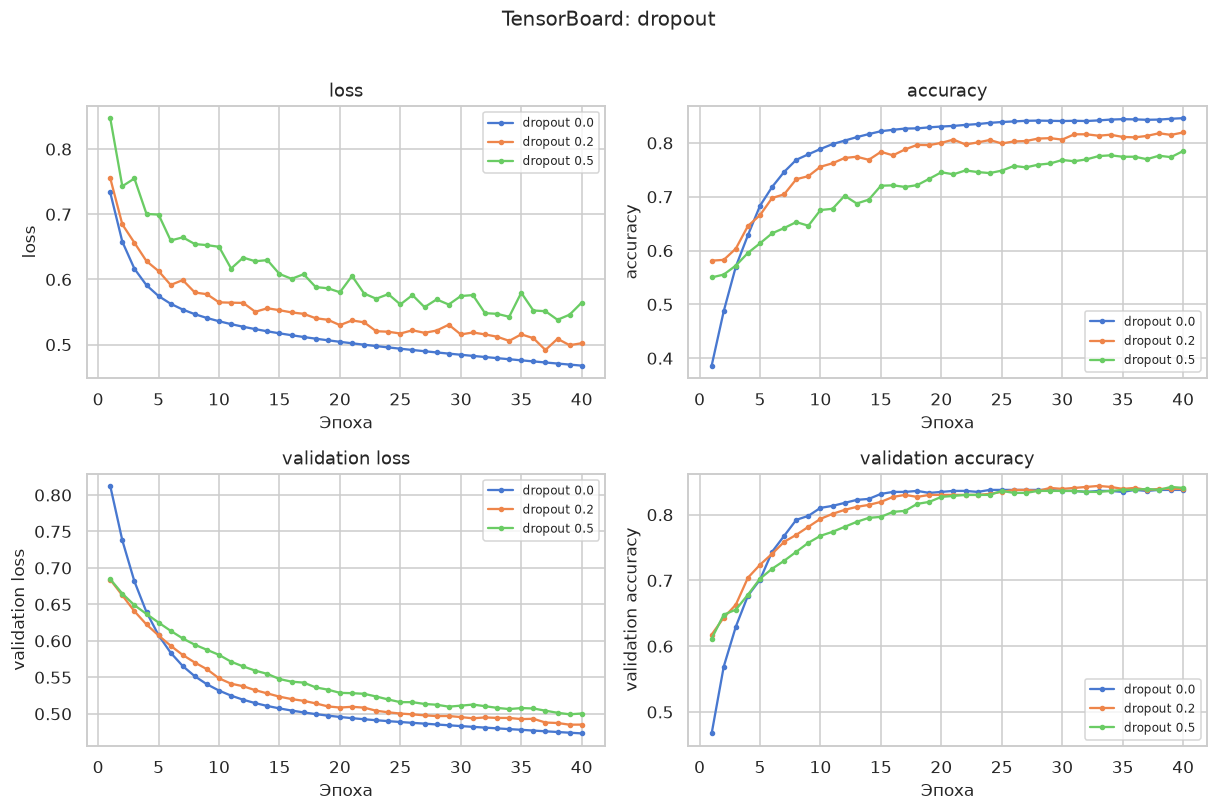

Оставлен dropout = 0.2
Итоговая архитектура: {'units': 64, 'learning_rate': 0.0001, 'dropout': 0.2, 'n_layers': 1, 'activation': 'relu', 'batch_size': 16, 'epochs': 40}


In [16]:
import tensorflow as tf
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.get_logger().setLevel("ERROR")

LOG_ROOT = Path("logs") / "tensorboard"
if LOG_ROOT.exists():
    shutil.rmtree(LOG_ROOT)
LOG_ROOT.mkdir(parents=True)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)
nn_scaler = StandardScaler()
X_fit_s = nn_scaler.fit_transform(X_fit)
X_val_s = nn_scaler.transform(X_val)
y_fit_f = y_fit.to_numpy().astype(np.float32)
y_val_f = y_val.to_numpy().astype(np.float32)
y_val_i = y_val.to_numpy().astype(int)


def class_weight_of(target):
    values = np.asarray(target).astype(int)
    return {label: float(len(values) / (2.0 * np.sum(values == label))) for label in (0, 1)}


NN_BASE = {
    "units": 32,
    "learning_rate": 1e-3,
    "dropout": 0.2,
    "n_layers": 2,
    "activation": "relu",
    "batch_size": 32,
    "epochs": 25,
}


def merge_cfg(**cfg):
    params = {**NN_BASE, **cfg}
    for key in ("units", "n_layers", "batch_size", "epochs"):
        params[key] = int(params[key])
    params["learning_rate"] = float(params["learning_rate"])
    params["dropout"] = float(params["dropout"])
    params["activation"] = str(params["activation"])
    return params


def run_name(params):
    return (
        f"L{params['n_layers']}_U{params['units']}_{params['activation']}"
        f"_lr{params['learning_rate']:.0e}_d{params['dropout']:.1f}"
        f"_bs{params['batch_size']}_ep{params['epochs']}"
    )


def build_mlp(n_features, params):
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    layers = [tf.keras.layers.Input(shape=(n_features,))]
    width = int(params["units"])
    for index in range(int(params["n_layers"])):
        layers.append(tf.keras.layers.Dense(width, activation=params["activation"]))
        if index == 0:
            layers.append(tf.keras.layers.Dropout(float(params["dropout"])))
        width = max(width // 2, 8)
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=float(params["learning_rate"])),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def read_tb(log_dir, split, key):
    candidates = {
        "loss": ["loss", "epoch_loss"],
        "accuracy": ["accuracy", "epoch_accuracy"],
    }[key]
    path = Path(log_dir) / split
    if not path.exists():
        return None
    accumulator = EventAccumulator(str(path), size_guidance={"scalars": 0, "tensors": 0})
    accumulator.Reload()
    tags = accumulator.Tags()
    scalar_tags = set(tags.get("scalars", []))
    tensor_tags = set(tags.get("tensors", []))
    for name in candidates:
        if name in scalar_tags:
            return [float(event.value) for event in accumulator.Scalars(name)]
        if name in tensor_tags:
            return [float(tf.make_ndarray(event.tensor_proto)) for event in accumulator.Tensors(name)]
    return None


NN_CACHE = {}


def train_run(**cfg):
    params = merge_cfg(**cfg)
    key = tuple(sorted(params.items()))
    if key in NN_CACHE:
        return NN_CACHE[key]
    name = run_name(params)
    log_dir = LOG_ROOT / name
    model = build_mlp(X_fit_s.shape[1], params)
    history = model.fit(
        X_fit_s, y_fit_f,
        validation_data=(X_val_s, y_val_f),
        epochs=params["epochs"],
        batch_size=params["batch_size"],
        class_weight=class_weight_of(y_fit),
        callbacks=[tf.keras.callbacks.TensorBoard(
            log_dir=str(log_dir), histogram_freq=0, write_graph=True, update_freq="epoch",
        )],
        verbose=0,
    )
    proba = model.predict(X_val_s, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)
    tb_loss = read_tb(log_dir, "validation", "loss")
    source = "TensorBoard"
    if tb_loss is None:
        source = "history"
        print(f"Журнал {name}: event-файл не прочитан, кривые берутся из history Keras")
    else:
        hist_last = float(history.history["val_loss"][-1])
        tb_last = float(tb_loss[-1])
        if abs(hist_last - tb_last) > 1e-4:
            print(f"Расхождение TensorBoard и history у {name}: {tb_last:.4f} против {hist_last:.4f}")
    row = {
        **params,
        "Прогон": name,
        "log_dir": str(log_dir),
        "history": history.history,
        "source": source,
        "val_auc": float(roc_auc_score(y_val_i, proba)),
        "val_recall": float(recall_score(y_val_i, pred, zero_division=0)),
        "val_f1": float(f1_score(y_val_i, pred, zero_division=0)),
        "val_loss": float(history.history["val_loss"][-1]),
        "gap_acc": float(history.history["accuracy"][-1] - history.history["val_accuracy"][-1]),
        "min_val_epoch": int(np.argmin(history.history["val_loss"]) + 1),
    }
    print(
        f"{name}: val AUC {row['val_auc']:.4f} | val loss {row['val_loss']:.4f} | "
        f"val recall {row['val_recall']:.4f} | источник кривых {source}"
    )
    NN_CACHE[key] = row
    return row


def pick_nn(rows):
    frame = pd.DataFrame([{k: v for k, v in row.items() if k != "history"} for row in rows])
    pool = frame[frame["val_auc"] >= frame["val_auc"].max() - 0.005].copy()
    best = pool.sort_values(["val_loss", "gap_acc"], ascending=[True, True]).iloc[0]
    return next(row for row in rows if row["Прогон"] == best["Прогон"])


def plot_nn(rows, label_of, title):
    panels = (
        ("train", "loss", "loss"),
        ("train", "accuracy", "accuracy"),
        ("validation", "loss", "validation loss"),
        ("validation", "accuracy", "validation accuracy"),
    )
    fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.2))
    for row in rows:
        for ax, (split, key, ylabel) in zip(axes.ravel(), panels):
            values = read_tb(row["log_dir"], split, key)
            if not values:
                hist_key = key if split == "train" else f"val_{key}"
                values = row["history"][hist_key]
            ax.plot(np.arange(1, len(values) + 1), values, marker="o", ms=2.6, label=label_of(row))
            ax.set_xlabel("Эпоха")
            ax.set_ylabel(ylabel)
            ax.set_title(ylabel)
    for ax in axes.ravel():
        ax.legend(fontsize=8)
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


print("Веса классов на подборе:", {k: round(v, 3) for k, v in class_weight_of(y_fit).items()})
print("Журнал TensorBoard:", LOG_ROOT.resolve())
print("Вход сети:", X_fit_s.shape[1], "признаков")

current = dict(NN_BASE)
sweeps = [
    ("learning_rate", (1e-4, 1e-3, 1e-2), lambda r: f"lr={r['learning_rate']:.0e}",
     "TensorBoard: скорость обучения"),
    ("units", (16, 32, 64), lambda r: f"{int(r['units'])} нейронов",
     "TensorBoard: ширина первого слоя"),
    ("n_layers", (1, 2, 3), lambda r: f"{int(r['n_layers'])} скрытых слоя",
     "TensorBoard: число скрытых слоёв"),
    ("activation", ("relu", "tanh"), lambda r: str(r["activation"]),
     "TensorBoard: функция активации"),
    ("batch_size", (16, 32, 128), lambda r: f"batch {int(r['batch_size'])}",
     "TensorBoard: размер батча"),
    ("epochs", (10, 25, 40), lambda r: f"{int(r['epochs'])} эпох",
     "TensorBoard: число эпох"),
    ("dropout", (0.0, 0.2, 0.5), lambda r: f"dropout {r['dropout']:.1f}",
     "TensorBoard: dropout"),
]
search_rows = []
for param, values, label_of, title in sweeps:
    rows = [train_run(**{**current, param: value}) for value in values]
    best_row = pick_nn(rows)
    current[param] = best_row[param]
    table = pd.DataFrame([{
        param: row[param],
        "val AUC": row["val_auc"],
        "val loss": row["val_loss"],
        "val recall": row["val_recall"],
        "val F1": row["val_f1"],
        "эпоха min val loss": row["min_val_epoch"],
    } for row in rows])
    display(table.round(4))
    plot_nn(rows, label_of, title)
    print(f"Оставлен {param} = {best_row[param]}")
    search_rows.extend(rows)

nn_choice = merge_cfg(**current)
print("Итоговая архитектура:", nn_choice)

Кривые loss должны убывать и на обучении, и на проверке. Если обучающий loss продолжает падать, а validation loss разворачивается вверх, сеть запоминает конкретных клиентов: лишние эпохи и лишняя ширина здесь вредны. Accuracy на тех же графиках легко стоит высоко с первой эпохи, потому что класс «отказ» большой. Поэтому в таблице рядом напечатаны val AUC и val recall, а не только accuracy.

Скорость обучения `1e-2` часто делает кривую loss дёрганой: шаг Adam слишком крупный для этой выборки. Слишком малая скорость за те же эпохи просто не доходит до плато. Ширина 16–64 и один-три слоя на четырёх тысячах клиентов — небольшой диапазон; если AUC почти не меняется, данных не хватает, чтобы окупить глубокую сеть, а не «глубокая сеть всегда лучше».

Dropout 0 убирает регуляризацию и обычно увеличивает разрыв обучения и проверки. Dropout 0,5 при такой ширине может начать выкидывать слишком много сигнала. Размер батча меняет шум градиента: маленький батч шумит сильнее, большой ближе к полному градиенту и на маленькой выборке иногда хуже обобщается.

Жадный перебор оставил один скрытый слой на 64 нейрона с ReLU, dropout 0,2, скорость обучения 10⁻⁴, батч 16 и 40 эпох. Проверочный AUC этой конфигурации 0,791. Второй и третий слои AUC не подняли. Скорость 10⁻² хуже 10⁻⁴: кривая менее устойчива. За 40 эпох validation loss ещё снижался, минимум ближе к концу, явного разворота нет, но прирост от 25 к 40 эпохам уже крошечный. Dropout 0,5 дал чуть более высокий проверочный AUC при худшем validation loss, поэтому остался 0,2.

### 7.1. Сеть на отложенном тесте

,Метод,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,"Сеть, веса классов",0.8313,0.3399,0.5778,0.4280,0.7358
1,"Сеть, без весов",0.9017,0.7143,0.1667,0.2703,0.7272
2,LDA,0.8993,0.5686,0.3222,0.4113,0.7784


Журнал финального обучения: D:\sharaga\AIslop\Lab2_Classification\logs\tensorboard\final_balanced


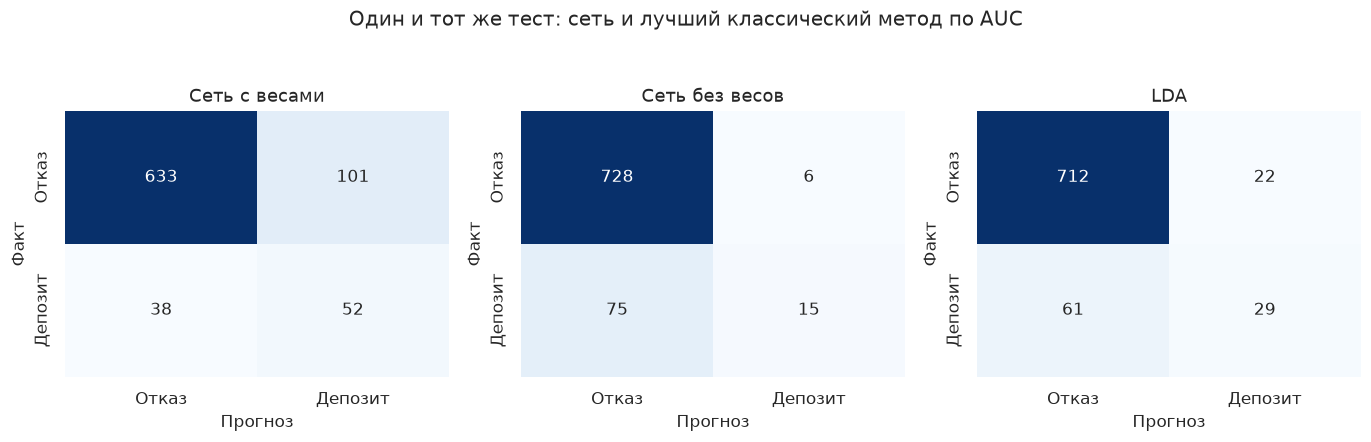

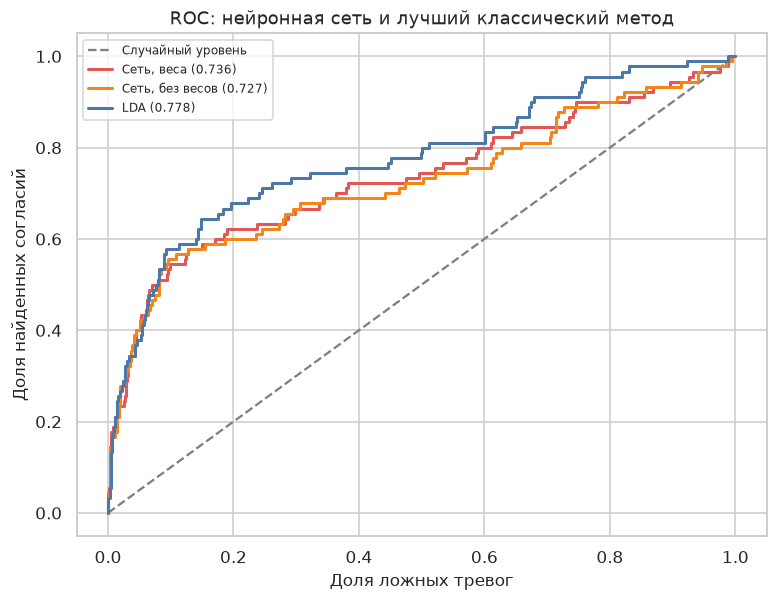

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 64)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
final_scaler = StandardScaler()
X_train_s = final_scaler.fit_transform(X_train)
X_test_s = final_scaler.transform(X_test)


def fit_final(class_weight, log_name):
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    log_dir = LOG_ROOT / log_name
    if log_dir.exists():
        shutil.rmtree(log_dir)
    model = build_mlp(X_train_s.shape[1], nn_choice)
    model.fit(
        X_train_s, y_train.to_numpy().astype(np.float32),
        epochs=nn_choice["epochs"],
        batch_size=nn_choice["batch_size"],
        class_weight=class_weight,
        callbacks=[tf.keras.callbacks.TensorBoard(
            log_dir=str(log_dir), histogram_freq=0, write_graph=True, update_freq="epoch",
        )],
        verbose=0,
    )
    return model


def score_nn(model, name):
    proba = model.predict(X_test_s, verbose=0).ravel()
    pred = (proba >= 0.5).astype(int)
    metrics = test_metrics(name, y_true, pred, proba)
    metrics["proba"] = proba
    metrics["pred"] = pred
    return metrics


nn_balanced = score_nn(fit_final(class_weight_of(y_train), "final_balanced"), "Сеть, веса классов")
nn_plain = score_nn(fit_final(None, "final_plain"), "Сеть, без весов")
classical_name = leader["Метод"]
compare_nn = pd.DataFrame([
    {key: nn_balanced[key] for key in ["Метод", "Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]},
    {key: nn_plain[key] for key in ["Метод", "Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]},
    report[report["Метод"] == classical_name].iloc[0].to_dict(),
]).reset_index(drop=True)
display(compare_nn.round(4))
print("Журнал финального обучения:", (LOG_ROOT / "final_balanced").resolve())

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.8))
for ax, pred, title in (
    (axes[0], nn_balanced["pred"], "Сеть с весами"),
    (axes[1], nn_plain["pred"], "Сеть без весов"),
    (axes[2], PREDS[classical_name], classical_name),
):
    matrix = confusion_matrix(y_true, pred, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Отказ", "Депозит"], yticklabels=["Отказ", "Депозит"])
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Факт")
    ax.set_title(title)
fig.suptitle("Один и тот же тест: сеть и лучший классический метод по AUC", y=1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Случайный уровень")
for proba, label, color in (
    (nn_balanced["proba"], f"Сеть, веса ({nn_balanced['AUC-ROC']:.3f})", "#E45756"),
    (nn_plain["proba"], f"Сеть, без весов ({nn_plain['AUC-ROC']:.3f})", "#F58518"),
    (SCORES[classical_name], f"{classical_name} ({leader['AUC-ROC']:.3f})", "#4C78A8"),
):
    fpr, tpr, _ = roc_curve(y_true, proba)
    ax.plot(fpr, tpr, lw=2, color=color, label=label)
ax.set_xlabel("Доля ложных тревог")
ax.set_ylabel("Доля найденных согласий")
ax.set_title("ROC: нейронная сеть и лучший классический метод")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

model_summary = build_mlp(X_train_s.shape[1], nn_choice)
model_summary.summary()

Финальная сеть заново учится на всём обучении и один раз проверяется на тесте. Масштаб признаков считается по обучению и только потом применяется к тесту. В сети 3521 параметр: 53 входа, 64 нейрона ReLU, dropout и один выход с сигмоидой.

С весами классов тест даёт AUC 0,736, recall 0,578, precision 0,340, accuracy 0,831. Без весов accuracy 0,902 и precision 0,714, но recall только 0,167: сеть снова прячется в отказ, AUC 0,727. Оба варианта ниже LDA (0,778). Проверочные 0,79 до теста не доехали. Кусок в 659 клиентов, по которому выбиралась архитектура, слишком мал, чтобы этот выбор перенёсся без запаса.

Признаки кампании в основном линейные: макроэкономика, канал связи, успех прошлой кампании. Один скрытый слой это подтвердил, второй и третий на подборе были хуже. Сеть здесь проверяет, что нелинейность не была упущена, и этой проверки она не проходит: LDA остаётся сильнее по ROC.

Журнал `logs/tensorboard/final_balanced` — это уже обучение выбранной сети на всех обучающих клиентах. Его можно открыть в TensorBoard вместе с журналами перебора.

## 8. Заключение

На телефонной кампании банка построена бинарная классификация «клиент откроет срочный депозит». Из 4119 клиентов согласились 10,9%, поэтому accuracy около 0,89 есть уже у правила «никому не звонить повторно с предложением». Сравнивать методы по одной accuracy нельзя.

Подготовка данных важнее выбора алгоритма в одном конкретном месте. `duration` поднимает качество, потому что длина разговора известна только вместе с итогом. Столбец исключён, как и просят авторы набора. Код `pdays = 999` заменён явным признаком «раньше не звонили». Категория `unknown` сохранена.

Четыре байесовских классификатора здесь не равноправны. GaussianNB соответствует непрерывным признакам. MultinomialNB и BernoulliNB применены после сжатия и бинаризации, потому что иначе вход для них незаконен: есть отрицательные макропоказатели, а счётчиков частот нет. ComplementNB — вариант той же схемы, поправленный на редкий класс. Дерево без ограничения глубины переобучается, это видно по разрыву train и CV. LDA и линейный SVM упираются в коррелирующие макропоказатели; shrinkage и штраф `C` этот эффект стабилизируют, но не создают нового признака. kNN при маленьком k запоминает соседей, при большом начинает повторять класс большинства.

Нейронная сеть — перцептрон с одним скрытым слоем на 64 нейрона ReLU, dropout 0,2, Adam со скоростью 10⁻⁴, батч 16, 40 эпох, сигмоида и бинарная кросс-энтропия. Кривые loss и accuracy записаны в TensorBoard и прочитаны оттуда в ноутбук. На тесте сеть с весами классов получает AUC 0,736 и recall 0,578, без весов — AUC 0,727 и recall 0,167. Оба результата ниже LDA.

Практический вывод для этого датасета такой. Ранжировать клиентов, кому звонить сначала, лучше всего умеет LDA: тестовый AUC 0,778. Готовый список «предсказанных согласий» при стандартном пороге лучше отдают BernoulliNB (F1 0,477, recall 0,522), ComplementNB и SVM с весами классов. Более глубокая сеть качества не добавляет: второй и третий слои на подборе были хуже одного, а на тесте перцептрон не обогнал линейную границу. Главный выигрыш дала не архитектура, а честная подготовка: без длительности звонка и без доверия к одной только accuracy.

Воспроизведение: запустить ноутбук сверху вниз при `RANDOM_STATE = 42`. Журнал TensorBoard лежит в `logs/tensorboard`.

## 9. Список источников

1. Moro S., Cortez P., Rita P. A Data-Driven Approach to Predict the Success of Bank Telemarketing. *Decision Support Systems*, 2014. DOI: 10.1016/j.dss.2014.03.001.
   Набор данных: UCI Machine Learning Repository, Bank Marketing.
   https://archive.ics.uci.edu/dataset/222/bank+marketing
2. Pedregosa F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2011.
   https://scikit-learn.org/stable/
3. Abadi M. et al. TensorFlow: Large-Scale Machine Learning on Heterogeneous Systems. 2015.
   https://www.tensorflow.org/
4. TensorBoard: визуализация обучения.
   https://www.tensorflow.org/tensorboard
5. James G., Witten D., Hastie T., Tibshirani R. *An Introduction to Statistical Learning*. Springer.
   Главы о дискриминантном анализе, методе опорных векторов, деревьях и оценке классификации.
6. Rennie J. D. M. et al. Tackling the Poor Assumptions of Naive Bayes Text Classifiers. ICML, 2003.
   Обоснование ComplementNB для несбалансированных классов.
7. Документация pandas: https://pandas.pydata.org/docs/